# GG4257 Assignment 2

## Introduction - How to replicate the code and get the required data

- All the data loaded in this notebook can be accessed through my onedrive folder named "Assignment2_data": https://universityofstandrews907-my.sharepoint.com/:f:/r/personal/xm32_st-andrews_ac_uk/_layouts/15/onedrive.aspx?id=%2Fpersonal%2Fxm32%5Fst%2Dandrews%5Fac%5Fuk%2FDocuments%2FAssignment2%5Fdata&share=cgp4%5FYfSWxWaQL4YyjfoR3zaEgUChDrE5%2DSMi9LzhhUltMPCR (the folder also contains a copy of this notebook just in case Github doesn't work)
- The url to the github repository where this notebook is saved is here: https://github.com/2662474984/UA-Repo-in-Github.git and this notebook is named "GG4257 assignment 2"

## Lab No 4

### Challenge 1

Link to the dashboard: https://uostandrews.maps.arcgis.com/apps/mapviewer/index.html?webmap=e29ede8dc4354be8ba07a4c652fc1ba5&center=-77.561581%2C37.554539&scale=144447.638572

The map is named "230005476"

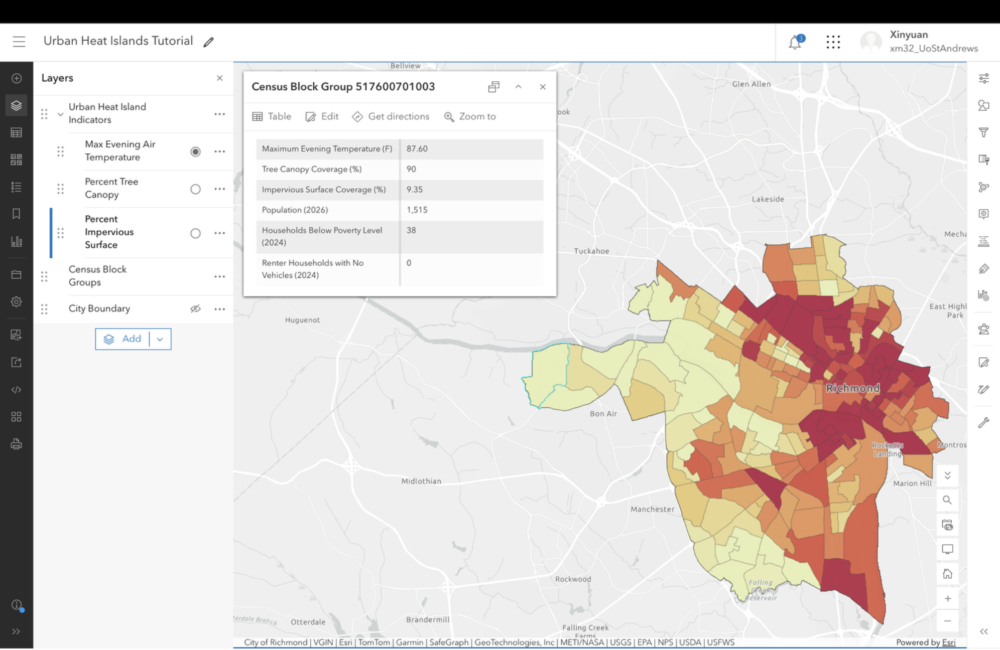

### Challenge 2

2.1 - Two static choropleth maps using different classification methods

In [10]:
import requests
import pandas as pd
import geopandas as gpd
import mapclassify as mc
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import plotly.io as pio

pio.renderers.default = "notebook_connected"

url_edinburgh = "https://maps.gov.scot/server/rest/services/ScotGov/PeopleSociety/MapServer/7/query?where=laname+%3D+%27City+of+Edinburgh%27&text=&objectIds=&time=&timeRelation=esriTimeRelationOverlaps&geometry=&geometryType=esriGeometryEnvelope&inSR=&spatialRel=esriSpatialRelIntersects&distance=&units=esriSRUnit_Foot&relationParam=&outFields=*&returnGeometry=true&returnTrueCurves=false&maxAllowableOffset=&geometryPrecision=&outSR=4326&havingClause=&returnIdsOnly=false&returnCountOnly=false&orderByFields=&groupByFieldsForStatistics=&outStatistics=&returnZ=false&returnM=false&gdbVersion=&historicMoment=&returnDistinctValues=false&resultOffset=&resultRecordCount=&returnExtentOnly=false&sqlFormat=none&datumTransformation=&parameterValues=&rangeValues=&quantizationParameters=&featureEncoding=esriDefault&f=geojson"

response = requests.get(url_edinburgh)
data = response.json()
edinburgh = gpd.GeoDataFrame.from_features(data["features"])
edinburgh = edinburgh.set_crs("EPSG:4326")

url_glasgow = "https://maps.gov.scot/server/rest/services/ScotGov/PeopleSociety/MapServer/7/query?where=laname+%3D+%27Glasgow+City%27&text=&objectIds=&time=&timeRelation=esriTimeRelationOverlaps&geometry=&geometryType=esriGeometryEnvelope&inSR=&spatialRel=esriSpatialRelIntersects&distance=&units=esriSRUnit_Foot&relationParam=&outFields=*&returnGeometry=true&returnTrueCurves=false&maxAllowableOffset=&geometryPrecision=&outSR=4326&havingClause=&returnIdsOnly=false&returnCountOnly=false&orderByFields=&groupByFieldsForStatistics=&outStatistics=&returnZ=false&returnM=false&gdbVersion=&historicMoment=&returnDistinctValues=false&resultOffset=&resultRecordCount=&returnExtentOnly=false&sqlFormat=none&datumTransformation=&parameterValues=&rangeValues=&quantizationParameters=&featureEncoding=esriDefault&f=geojson"

response = requests.get(url_glasgow)
data = response.json()
glasgow = gpd.GeoDataFrame.from_features(data["features"])
glasgow = glasgow.set_crs("EPSG:4326")

print("Edinburgh data zones:", len(edinburgh))
print("Glasgow data zones:", len(glasgow))

print(edinburgh.total_bounds)
print(glasgow.total_bounds)

Edinburgh data zones: 597
Glasgow data zones: 746
[-3.44952928 55.81879138 -3.07768043 56.01217038]
[-4.39239273 55.7812749  -4.07170516 55.92963532]


In [11]:
# check the attributes 
edinburgh.columns

Index(['geometry', 'objectid', 'datazone', 'dzname', 'laname', 'sape2017',
       'wape2017', 'rankv2', 'quintilev2', 'decilev2', 'vigintilv2',
       'percentv2', 'incrate', 'incnumdep', 'incrankv2', 'emprate',
       'empnumdep', 'emprank', 'hlthcif', 'hlthalcsr', 'hlthdrugsr', 'hlthsmr',
       'hlthdprspc', 'hlthlbwtpc', 'hlthemergs', 'hlthrank', 'eduattend',
       'eduattain', 'edunoquals', 'edupartici', 'eduuniver', 'edurank',
       'gaccpetrol', 'gaccdtgp', 'gaccdtpost', 'gaccdtpsch', 'gaccdtssch',
       'gaccdtret', 'gaccptgp', 'gaccptpost', 'gaccptret', 'gaccbrdbnd',
       'gaccrank', 'crimecount', 'crimerate', 'crimerank', 'housenumoc',
       'housenumnc', 'houseocrat', 'housencrat', 'houserank', 'shape_leng',
       'st_area(shape)', 'st_length(shape)'],
      dtype='object')

In [12]:
glasgow.columns

Index(['geometry', 'objectid', 'datazone', 'dzname', 'laname', 'sape2017',
       'wape2017', 'rankv2', 'quintilev2', 'decilev2', 'vigintilv2',
       'percentv2', 'incrate', 'incnumdep', 'incrankv2', 'emprate',
       'empnumdep', 'emprank', 'hlthcif', 'hlthalcsr', 'hlthdrugsr', 'hlthsmr',
       'hlthdprspc', 'hlthlbwtpc', 'hlthemergs', 'hlthrank', 'eduattend',
       'eduattain', 'edunoquals', 'edupartici', 'eduuniver', 'edurank',
       'gaccpetrol', 'gaccdtgp', 'gaccdtpost', 'gaccdtpsch', 'gaccdtssch',
       'gaccdtret', 'gaccptgp', 'gaccptpost', 'gaccptret', 'gaccbrdbnd',
       'gaccrank', 'crimecount', 'crimerate', 'crimerank', 'housenumoc',
       'housenumnc', 'houseocrat', 'housencrat', 'houserank', 'shape_leng',
       'st_area(shape)', 'st_length(shape)'],
      dtype='object')

In [13]:
num_classes = 5 # setting the number of classes

# classified using natural breaks 
classifier_nb = mc.NaturalBreaks(
    edinburgh["crimerate"], k=num_classes
)

# classified using quantiles
classifier_quant = mc.Quantiles(
    edinburgh["crimerate"], k=num_classes
)

print(classifier_nb)
print(classifier_quant)

NaturalBreaks

     Interval        Count
--------------------------
[   0.00,  307.00] |   362
( 307.00,  708.00] |   187
( 708.00, 1556.00] |    41
(1556.00, 3750.00] |     6
(3750.00, 7035.00] |     1
Quantiles

     Interval        Count
--------------------------
[   0.00,  132.20] |   120
( 132.20,  201.00] |   120
( 201.00,  304.00] |   118
( 304.00,  467.80] |   119
( 467.80, 7035.00] |   120


In [ ]:
# plot the histogram and visualise how the data is classified 
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

sns.histplot(
    data=edinburgh, x="crimerate",
    ax=axes[0], kde=True, bins=20
)

axes[0].axvline(
    classifier_nb.bins[0],
    color="red", linestyle="dashed",
    linewidth=2, label="Natural Breaks"
)

for bin_value in classifier_nb.bins:
    axes[0].axvline(
        bin_value, color="red",
        linestyle="dashed", linewidth=2
    )

axes[0].set_title("Edinburgh crime rate: Natural Breaks")
axes[0].legend()

sns.histplot(
    data=edinburgh, x="crimerate",
    ax=axes[1], kde=True, bins=20
)

axes[1].axvline(
    classifier_quant.bins[0],
    color="blue", linestyle="dashed",
    linewidth=2, label="Quantiles"
)

for bin_value in classifier_quant.bins:
    axes[1].axvline(
        bin_value, color="blue",
        linestyle="dashed", linewidth=2
    )

axes[1].set_title("Edinburgh crimerate: Quantiles")
axes[1].legend()

plt.tight_layout()
plt.show()

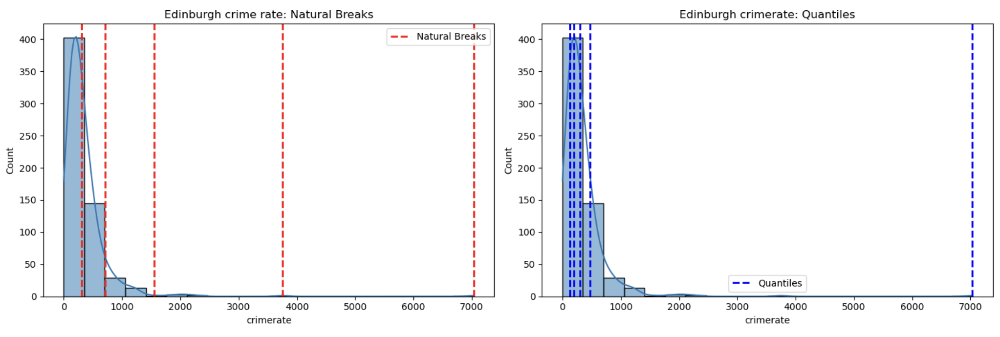

In [ ]:
# plot the crime rate across Edinburgh
fig, axs = plt.subplots(1, 2, figsize=(18, 8))

edinburgh.to_crs(27700).plot(
    column="crimerate",
    ax=axs[0],
    legend=True,
    cmap="viridis",
    scheme="UserDefined",
    classification_kwds={"bins": classifier_nb.bins}
)

axs[0].set_title("Edinburgh crimerate: Natural Breaks")

edinburgh.to_crs(27700).plot(
    column="crimerate",
    ax=axs[1],
    legend=True,
    cmap="viridis",
    scheme="UserDefined",
    classification_kwds={"bins": classifier_quant.bins}
)

axs[1].set_title("Edinburgh crimerate: Quantiles")

plt.tight_layout()
plt.show()

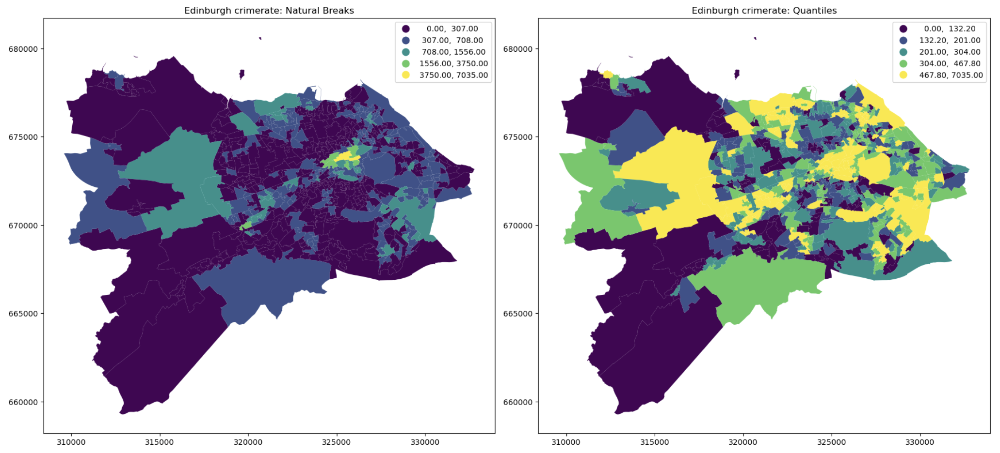

**2.1 concluding remarks:** The histograms show a strongly right-skewed distribution. Most data zones have relatively low crime rates, while a few extreme values extend the range to 7,035.

Natural Breaks groups areas with similar crime rates. Its class boundaries are approximately 307, 708, 1,556, 3,750 and 7,035. Most areas appear purple or blue, while exceptionally high values form a small yellow cluster near the centre. This emphasises extreme hotspots but shows less variation among lower-crime rate areas.

Quantiles places approximately 20% of data zones in each of the five classes. The first four boundaries are concentrated below 468, revealing more variation across the city. However, its highest class spans 467.8–7,035, so moderately high and extremely high rates receive the same yellow colour.

Consequently, Natural Breaks highlights differences in magnitude, whereas Quantiles highlights areas’ relative positions within Edinburgh. The larger yellow area on the Quantile map results from different thresholds, rather than any change in crime rates.

In [ ]:
# creating choropleth map showing deprivation using the 'rankv2' attribute
# according to the metadata, the rankv2 ranks the 6976 zones in Scotland from the least deprived (highest rankv2) to the most
# deprived (lowest rankv2)
fig = px.choropleth_map(
    edinburgh,
    geojson=edinburgh.geometry,
    locations=edinburgh.index,
    color="rankv2",
    color_continuous_scale="RdYlBu",
    range_color=(1, 6976),
    labels={"rankv2": "SIMD rank"},
    opacity=0.8,
    center={"lat": 55.95, "lon": -3.19},
    map_style="carto-positron",
    zoom=10
)

fig.update_layout(
    title="Edinburgh: SIMD 2020 deprivation",
    margin={"r": 0, "t": 40, "l": 0, "b": 0}
)
fig.show()
# red represents more deprived zones

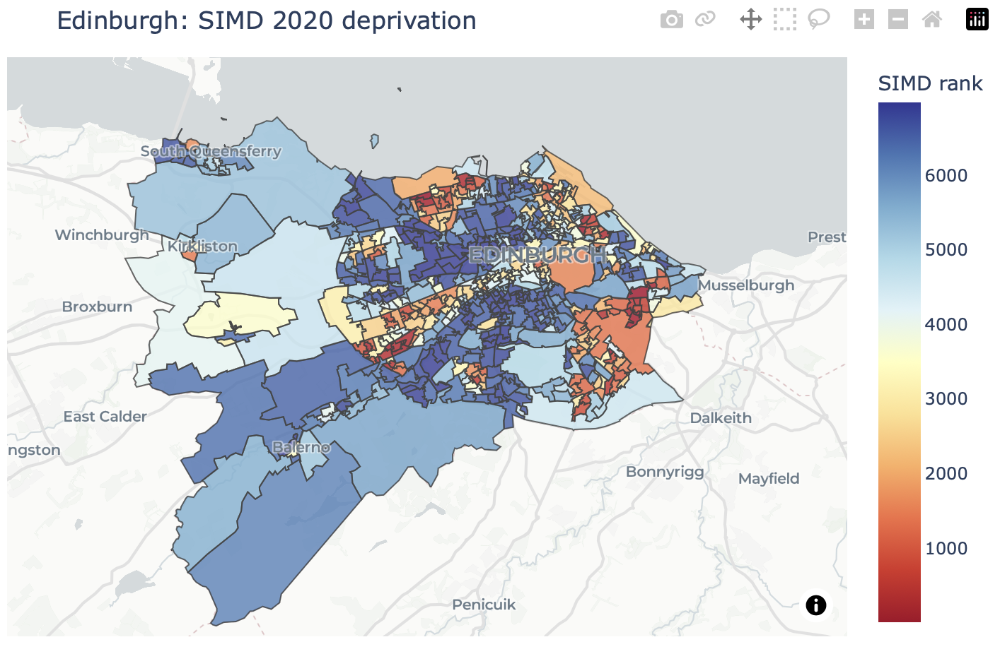

In [ ]:
fig = px.choropleth_map(
    glasgow,
    geojson=glasgow.geometry,
    locations=glasgow.index,
    color="rankv2",
    color_continuous_scale="RdYlBu",
    range_color=(1, 6976),
    labels={"rankv2": "SIMD rank"},
    opacity=0.8,
    center={"lat": 55.866193, "lon": -4.258246},
    map_style="carto-positron",
    zoom=10
)

fig.update_layout(
    title="Glasgow: SIMD 2020 deprivation",
    margin={"r": 0, "t": 40, "l": 0, "b": 0}
)
fig.show()

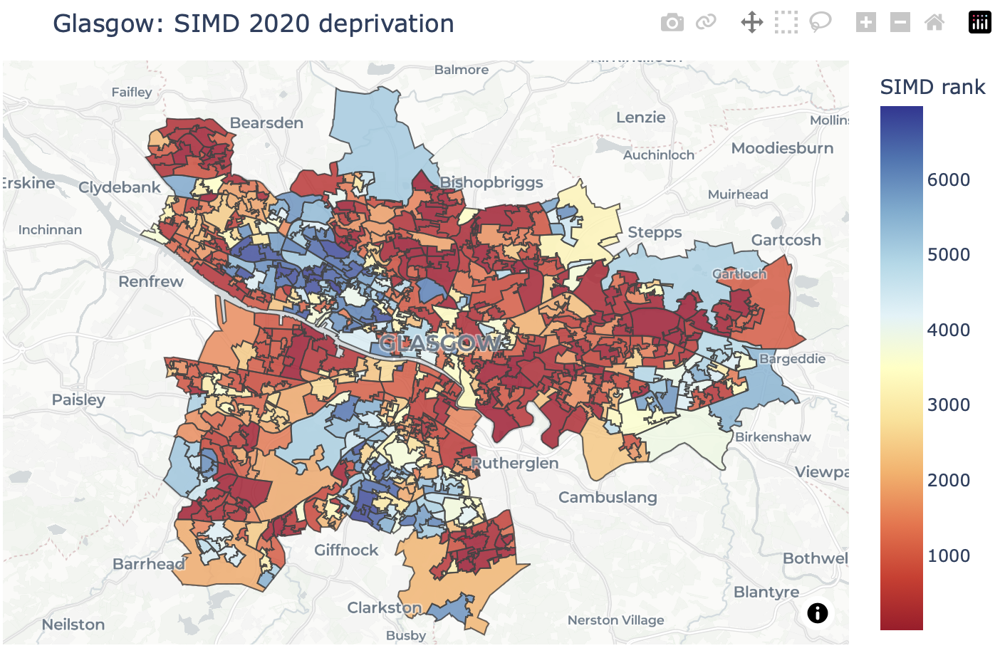

**2.2 concluding remarks:** Overall, Glasgow shows more widespread concentrations of deprivation than Edinburgh.

In Edinburgh, blue areas dominate much of the centre, west, and southwest. More deprived areas form smaller clusters along the northern edge, in the southeast, and in parts of the west. This shows substantial inequalities within a city containing many relatively less deprived neighbourhoods.

In Glasgow, red and orange areas extend across much of the north and east. The River Clyde divides western Glasgow, where north of the river shows a lower deprivation level, whereas orange to red zones cluster south of it. Less deprived areas cluster particularly in the west and parts of the south, often close to more deprived neighbourhoods.

## Lab No 5 - Growth And Accessibility: 7 challenges

### Challenge 1

In [69]:
import os
import math
import getpass
import requests
import pandas as pd
import geopandas as gpd
import numpy as np
import networkx as nx
import osmnx as ox
import matplotlib.pyplot as plt
from shapely.ops import unary_union

print("Ready! OSMnx version", ox.__version__)
print("Files in data/:", sorted(os.listdir("data5")))

Ready! OSMnx version 1.5.0
Files in data/: ['EDI_DataZones', 'EconomicEDI.csv', 'SG_SIMD_2020.zip', 'city_buildings.gpkg', 'city_parks.gpkg', 'city_walk.graphml', 'dundee_overture_places.gpkg', 'dundee_services.gpkg', 'dundee_walk.graphml', 'edinburgh_growth.csv', 'edinburgh_north_services.gpkg', 'ohsome_edinburgh_north_count_timeline_2026-01-01.json', 'ohsome_edinburgh_north_length_timeline_2026-01-01.json', 'ohsome_edinburgh_north_streets_by_datazone_2012-01-01_2026-01-01.json', 'ohsome_metadata.json', 'perth_bike.graphml', 'perth_residential.gpkg', 'perth_services.gpkg', 'perth_walk.graphml']


In [70]:
API_KEY = getpass.getpass("eyJvcmciOiI1YjNjZTM1OTc4NTExMTAwMDFjZjYyNDgiLCJpZCI6ImRmYzAzZDFmYmRmOTQ4ZWZhMDZiZjE3Yjg5N2E4Yjk0IiwiaCI6Im11cm11cjY0In0=")

eyJvcmciOiI1YjNjZTM1OTc4NTExMTAwMDFjZjYyNDgiLCJpZCI6ImRmYzAzZDFmYmRmOTQ4ZWZhMDZiZjE3Yjg5N2E4Yjk0IiwiaCI6Im11cm11cjY0In0= ········


In [81]:
OHSOME_URL = "https://api.heigit.org/ohsome-api/v2-rc/stats/features/"
BBOX = [-2.835503,56.326865,-2.767439,56.344374]          # St Andrews 

def ohsome(measure, osm_filter):
    body = {"aoi": BBOX,
            "filter": osm_filter,
            "time": {"start": "2008-01-01", "end": "2026-01-01", "interval": "P1Y"}}
    response = requests.post(OHSOME_URL + measure + ".json", json=body,
                             headers={"Authorization": API_KEY}, timeout=300)
    response.raise_for_status()               # stops here with a message if something went wrong
    result = response.json()["result"]
    years = [int(t[:4]) for t in result["timestamp"]]
    return pd.Series(result["value"], index=years)

buildings = ohsome("count", "building=* and geometry:polygon")
streets = ohsome("length", "highway in (residential, living_street) and type:way") / 1000   # metres -> km

growth = pd.DataFrame({"Buildings (count)": buildings, "Residential streets (km)": streets})
growth

,Buildings (count),Residential streets (km)
2008,0,4.734
2009,23,17.682
2010,33,22.442
2011,49,25.020
2012,63,38.300
2013,126,39.059
2014,179,39.448
2015,294,39.928
2016,340,36.631
2017,720,37.007


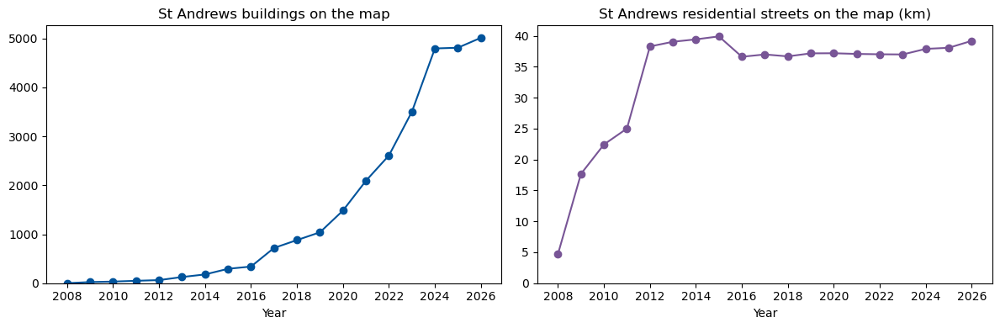

Change from 2012 to 2026 (%):
Buildings (count)           7859.0
Residential streets (km)       2.0
dtype: float64


In [77]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
growth["Buildings (count)"].plot(ax=axes[0], marker="o", color="#00539B", title="St Andrews buildings on the map")
growth["Residential streets (km)"].plot(ax=axes[1], marker="o", color="#785596", title="St Andrews residential streets on the map (km)")
for ax in axes:
    ax.set_ylim(bottom=0)
    ax.set_xlabel("Year")
    ax.xaxis.set_major_locator(plt.MaxNLocator(integer=True))   # whole years on the axis
plt.tight_layout()
plt.show()

change = (growth.loc[2026] / growth.loc[2012] - 1) * 100
print("Change from 2012 to 2026 (%):")
print(change.round(0))

**Challenge 1 concluding remarks**: St Andrews shows a similar pattern to north Edinburgh -- mapped residential street length stabilises in 2012, while mapped building counts increase substantially all the way til 2024. This suggests that the building increases largely reflect improvements in OpenStreetMap coverage rather than equivalent increases in construction. However, the timing differs between the two areas, indicating that mapping completeness develops unevenly across locations.

### Challenge 2

2.1

In [78]:
WALK_SPEED = 80                    # metres per minute (4.8 km/h)

G = ox.load_graphml("Assignment2_data/dundee_walk.graphml")
G = ox.project_graph(G, to_crs="EPSG:27700")            # British National Grid: distances in metres
nodes, edges = ox.graph_to_gdfs(G)

dundee_services = gpd.read_file("Assignment2_data/dundee_services.gpkg").to_crs("EPSG:27700")
print(dundee_services["service"].value_counts())

GP = dundee_services[dundee_services["service"] == "GP"].copy()
print(len(nodes), "street junctions and", len(GP), "GP")

service
Food shop    104
School        28
Pharmacy      19
GP            11
Name: count, dtype: int64
12777 street junctions and 11 GP


In [79]:
GP["node"] = ox.distance.nearest_nodes(G, GP.geometry.x, GP.geometry.y)
GP[["name", "node"]].head()

,name,node
123,Erskine Practice,12630357271
124,Mill Practice,12630357271
125,Hillbank Health Centre,12730677680
126,Terra Nova,12480649121
127,Hutcheson Podiatry,6651632775


In [ ]:
# Walking time to the nearest GP
nearest = nx.multi_source_dijkstra_path_length(G, set(GP["node"]), weight="length")
nodes["nearest_min"] = pd.Series(nearest) / WALK_SPEED

ax = nodes.plot(column="nearest_min", cmap="Oranges", markersize=2, legend=True, figsize=(8, 8), #Removing the time limit
                legend_kwds={"label": "Minutes to nearest GP"})
GP.plot(ax=ax, color="black", markersize=12)
ax.set_title("Measure 1: nearest GP (black dots = GP)")
ax.set_axis_off()
plt.show()

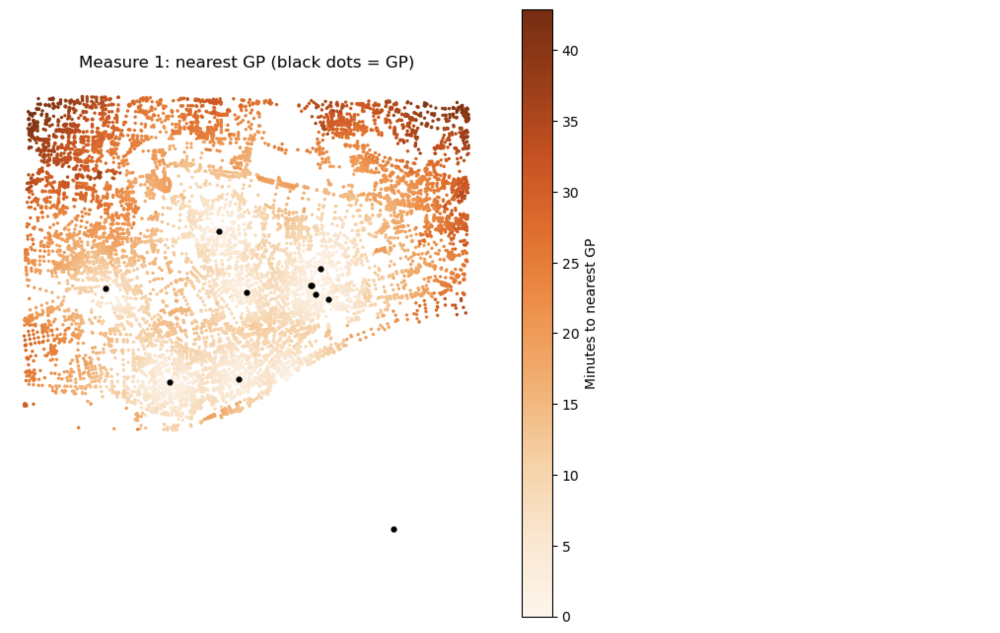

In [83]:
BETA = 0.069 

cumulative = {node: 0 for node in G.nodes}      
gravity = {node: 0.0 for node in G.nodes}

for GP_node in GP["node"]:
    distances = nx.single_source_dijkstra_path_length(G, GP_node, cutoff=30 * WALK_SPEED, weight="length")
    for node, metres in distances.items():
        minutes = metres / WALK_SPEED
        if minutes <= 10:
            cumulative[node] += 1
        gravity[node] += math.exp(-BETA * minutes)

nodes["cumulative"] = pd.Series(cumulative)
nodes["gravity"] = pd.Series(gravity)

nodes[["nearest_min", "cumulative", "gravity"]].describe().round(2)

,nearest_min,cumulative,gravity
count,12777.00,12777.00,12777.00
mean,16.01,0.70,1.53
std,10.11,1.24,1.38
min,0.00,0.00,0.00
25%,7.36,0.00,0.24
50%,13.72,0.00,1.10
75%,24.26,1.00,2.76
max,42.92,5.00,5.20


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6.5))
nodes.plot(ax=axes[0], column="cumulative", cmap="Blues", markersize=2, legend=True)
axes[0].set_title("GPs within a 10-minute walk")
nodes.plot(ax=axes[1], column="gravity", cmap="Purples", markersize=2, legend=True)
axes[1].set_title("Gravity score (BETA=0.069)")
for ax in axes:
    ax.set_axis_off()
plt.show()

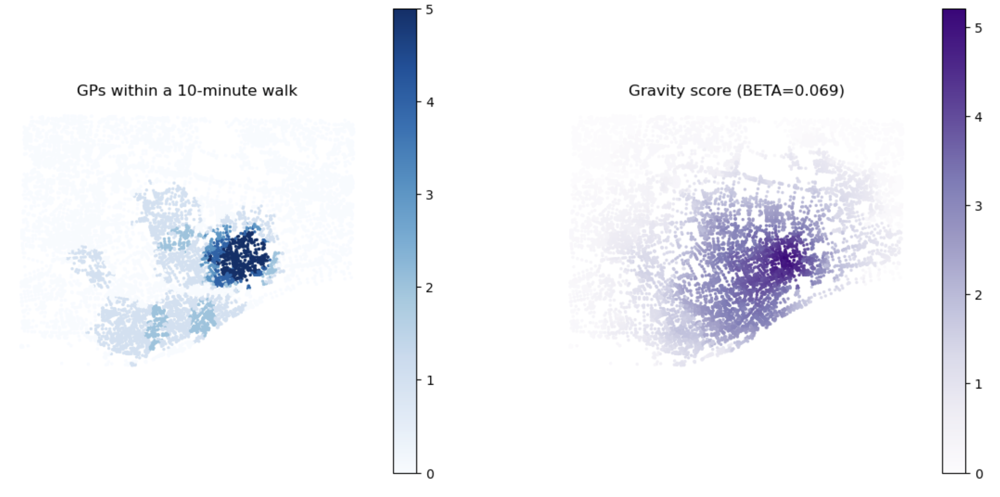

2.2

In [85]:
BETA_ = 0.14

cumulative = {node: 0 for node in G.nodes}      
gravity = {node: 0.0 for node in G.nodes}

for GP_node in GP["node"]:
    distances = nx.single_source_dijkstra_path_length(G, GP_node, cutoff=30 * WALK_SPEED, weight="length")
    for node, metres in distances.items():
        minutes = metres / WALK_SPEED
        if minutes <= 10:
            cumulative[node] += 1
        gravity[node] += math.exp(-BETA_ * minutes)

nodes["cumulative"] = pd.Series(cumulative)
nodes["gravity"] = pd.Series(gravity)

nodes[["nearest_min", "cumulative", "gravity"]].describe().round(2)

,nearest_min,cumulative,gravity
count,12777.00,12777.00,12777.00
mean,16.01,0.70,0.60
std,10.11,1.24,0.69
min,0.00,0.00,0.00
25%,7.36,0.00,0.05
50%,13.72,0.00,0.30
75%,24.26,1.00,1.02
max,42.92,5.00,3.88


In [ ]:
fig, ax = plt.subplots(figsize=(8, 8))

nodes.plot(ax=ax, column="gravity", cmap="Purples", markersize=2, legend=True)
ax.set_title("Gravity score (BETA=0.14)")
ax.set_axis_off()

plt.show()

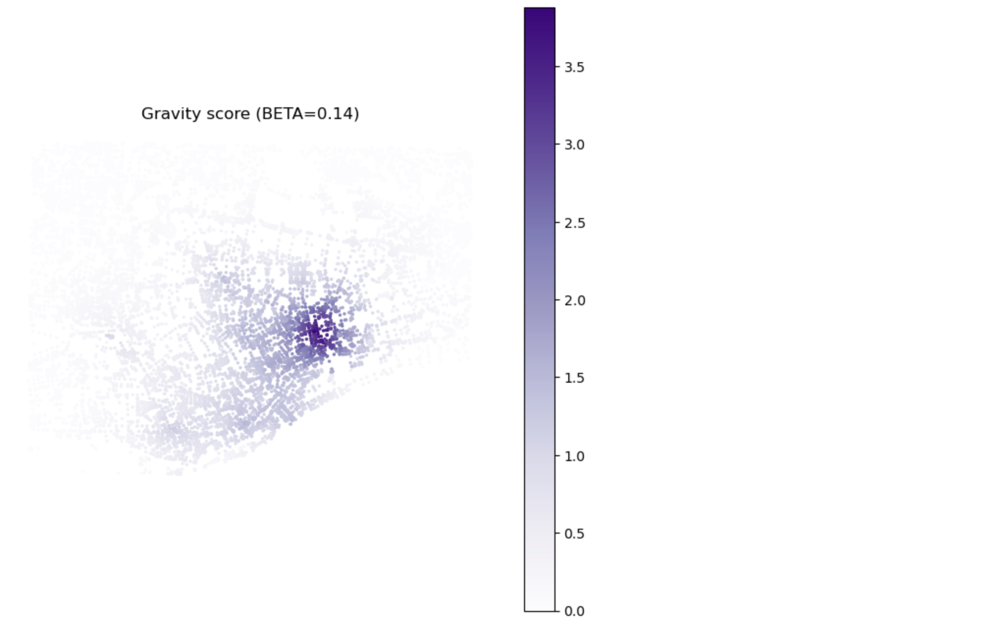

Explanation: Using a higher BETA assigns more weight to the distance travelled to reach the nearest GP. BETA = 0.14 means the distance contribution decays by 50% at a travel time of 5 minutes. Nearby GPs, therefore, matter more. A higher BETA is useful in areas where people are more sensitive to travel time. 

### Challenge 3

#### 3.1

In [87]:
%pip install overturemaps
import overturemaps

Note: you may need to restart the kernel to use updated packages.


In [93]:
DUNDEE_BOX = (-3.024, 56.438, -2.926, 56.492)        # west, south, east, north

table = overturemaps.record_batch_reader("place", bbox=DUNDEE_BOX, stac=True).read_all()
places = table.to_pandas()
places["geometry"] = gpd.GeoSeries.from_wkb(places["geometry"])
places = gpd.GeoDataFrame(places, geometry="geometry", crs="EPSG:4326").to_crs("EPSG:27700")
places["name"] = places["names"].str.get("primary")   # each place can have several names; keep the main one

print(len(places), "Overture places in Dundee")

6657 Overture places in Dundee


In [94]:
is_food = places["basic_category"].str.contains("grocery|supermarket|convenience", na=False)
overture_shops = places[is_food & (places["confidence"] >= 0.8)].copy()

print(overture_shops["basic_category"].value_counts())
print()
print("Food shops in OpenStreetMap:", len(shops))
print("Food shops in Overture:     ", len(overture_shops))

basic_category
convenience_store    90
Name: count, dtype: int64

Food shops in OpenStreetMap: 104
Food shops in Overture:      90


In [95]:
overture_shops["node"] = ox.distance.nearest_nodes(G, overture_shops.geometry.x, overture_shops.geometry.y)
nearest_overture = nx.multi_source_dijkstra_path_length(G, set(overture_shops["node"]), weight="length")
nodes["nearest_min_overture"] = pd.Series(nearest_overture) / WALK_SPEED

comparison = pd.DataFrame({
    "OpenStreetMap": [nodes["nearest_min"].median(), (nodes["nearest_min"] <= 10).mean() * 100],
    "Overture":      [nodes["nearest_min_overture"].median(), (nodes["nearest_min_overture"] <= 10).mean() * 100],
}, index=["Median minutes to nearest food shop", "% of junctions within 10 minutes"])
comparison.round(1)

,OpenStreetMap,Overture
Median minutes to nearest food shop,13.7,4.7
% of junctions within 10 minutes,37.7,81.9


The median minutes to nearest food shop remains the same. The percentage of junctions within 10 minutes decreased from 87.7% to 81.9%. 

#### 3.2

In [96]:
# Filtering the pharmacy in overturemap
pharmacy = places["basic_category"].str.contains("pharmacy", na=False)
overture_pharmacy = places[pharmacy & (places["confidence"] >= 0.5)].copy()

print(overture_pharmacy["basic_category"].value_counts())

basic_category
pharmacy_and_drug_store    34
Name: count, dtype: int64


In [97]:
# Getting the count of pharmacies in OpenStreet Map
openstreet_pharmacy = dundee_services[dundee_services["service"] == "Pharmacy"].copy()
print(len(openstreet_pharmacy), "pharmacies in OpenStreet Map")

19 pharmacies in OpenStreet Map


In [ ]:
fig, ax = plt.subplots(figsize=(9, 9))
edges.plot(ax=ax, color="lightgrey", linewidth=0.3)
openstreet_pharmacy.plot(ax=ax, color="#00539B", markersize=20, label="OpenStreetMap", alpha=0.7)
overture_pharmacy.plot(ax=ax, color="#F4C900", markersize=12, label="Overture", edgecolor="black", linewidth=0.3)
ax.legend(loc="lower left")
ax.set_title("Pharmacy in Dundee: OpenStreetMap (blue) and Overture (yellow)")
ax.set_axis_off()
plt.show()

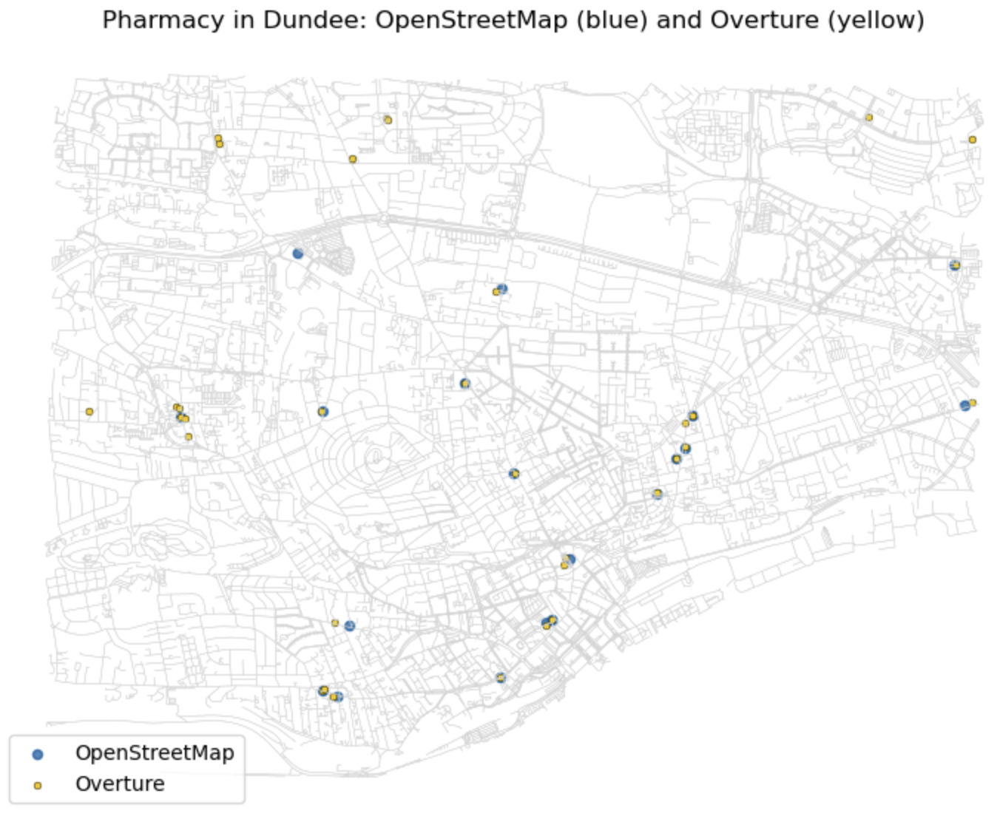

With a confidence threshold of 0.5, Overture returned more pharmacies than OpenStreetMap (34 vs. 19), although the difference was smaller than for food shops. This may reflect more consistent categorisation of pharmacies across the two datasets, whereas food shops include a wider variety of basic categories. Most OpenStreetMap pharmacy locations also overlap with those in Overture, suggesting greater agreement between the sources for pharmacies. 

### Challenge 4

In [99]:
PERTH = (56.3960, -3.4370)       
AREA = 1500                       
WALK_LIMIT = 800           # 10-min walking
BIKE_LIMIT = 2500          # 10-min biking     

SERVICES = {
    "School":           {"amenity": "school"},
    "Food shop":        {"shop": ["supermarket", "convenience", "greengrocer"]},
    "Healthcare":       {"amenity": ["doctors", "clinic", "pharmacy", "hospital"]},
    "Park":             {"leisure": "park"},
    "Public transport": {"highway": "bus_stop", "railway": "station"},
}

In [100]:
G_walk = ox.load_graphml("Assignment2_data/perth_walk.graphml")
G_walk = ox.project_graph(G_walk, to_crs="EPSG:27700").to_undirected()

G_bike = ox.load_graphml("Assignment2_data/perth_bike.graphml")
G_bike = ox.project_graph(G_bike, to_crs="EPSG:27700").to_undirected()

print("Walk network:", len(G_walk), "junctions | Bike network:", len(G_bike), "junctions")

Walk network: 6595 junctions | Bike network: 9236 junctions


In [101]:
walk_nodes, walk_edges = ox.graph_to_gdfs(G_walk)

residential = gpd.read_file("Assignment2_data/perth_residential.gpkg").to_crs("EPSG:27700")
residential_area = unary_union(list(residential.geometry))

centre = gpd.GeoSeries.from_xy([PERTH[1]], [PERTH[0]], crs="EPSG:4326").to_crs("EPSG:27700")
neighbourhood = centre.buffer(AREA).iloc[0]

homes = walk_nodes[walk_nodes.within(residential_area) & walk_nodes.within(neighbourhood)].copy()
print(len(homes), "residential junctions in the neighbourhood")

1067 residential junctions in the neighbourhood


In [102]:
services = gpd.read_file("Assignment2_data/perth_services.gpkg").to_crs("EPSG:27700")
homes_on_bike = ox.distance.nearest_nodes(G_bike, homes.geometry.x, homes.geometry.y)   # the same homes on the bike network

for name in SERVICES:
    points = services[services["service"] == name].geometry

    walk_targets = ox.distance.nearest_nodes(G_walk, points.x, points.y)
    bike_targets = ox.distance.nearest_nodes(G_bike, points.x, points.y)
    walk_dist = nx.multi_source_dijkstra_path_length(G_walk, set(walk_targets), weight="length")
    bike_dist = nx.multi_source_dijkstra_path_length(G_bike, set(bike_targets), weight="length")

    homes[name + " walk (m)"] = [walk_dist.get(n) for n in homes.index]
    homes[name + " bike (m)"] = [bike_dist.get(n) for n in homes_on_bike]
    print(f"{name:<17} {len(points):>5} found")

School               31 found
Food shop            48 found
Healthcare           29 found
Park                 28 found
Public transport    464 found


In [103]:
results = pd.DataFrame(index=list(SERVICES))
results["% homes within 10-min walk"] = [(homes[s + " walk (m)"] <= WALK_LIMIT).mean() * 100 for s in SERVICES]
results["% homes within 10-min cycle"] = [(homes[s + " bike (m)"] <= BIKE_LIMIT).mean() * 100 for s in SERVICES]
results.round(0)

,% homes within 10-min walk,% homes within 10-min cycle
School,65.0,100.0
Food shop,77.0,100.0
Healthcare,68.0,100.0
Park,65.0,100.0
Public transport,100.0,100.0


In [ ]:
homes["services_walk"] = sum((homes[s + " walk (m)"] <= WALK_LIMIT).astype(int) for s in SERVICES)

ax = homes.plot(column="services_walk", cmap="RdYlGn", vmin=0, vmax=5, markersize=6, legend=True,
                figsize=(8, 8), legend_kwds={"label": "Essential services within a 15-minute walk (of 5)"})
gpd.GeoSeries([neighbourhood], crs="EPSG:27700").boundary.plot(ax=ax, color="grey")
ax.set_title("Perth: is it a 15-minute neighbourhood?")
ax.set_axis_off()
plt.show()
 
print(f"{(homes['services_walk'] == 5).mean():.0%} of residential junctions reach all 5 services on foot")

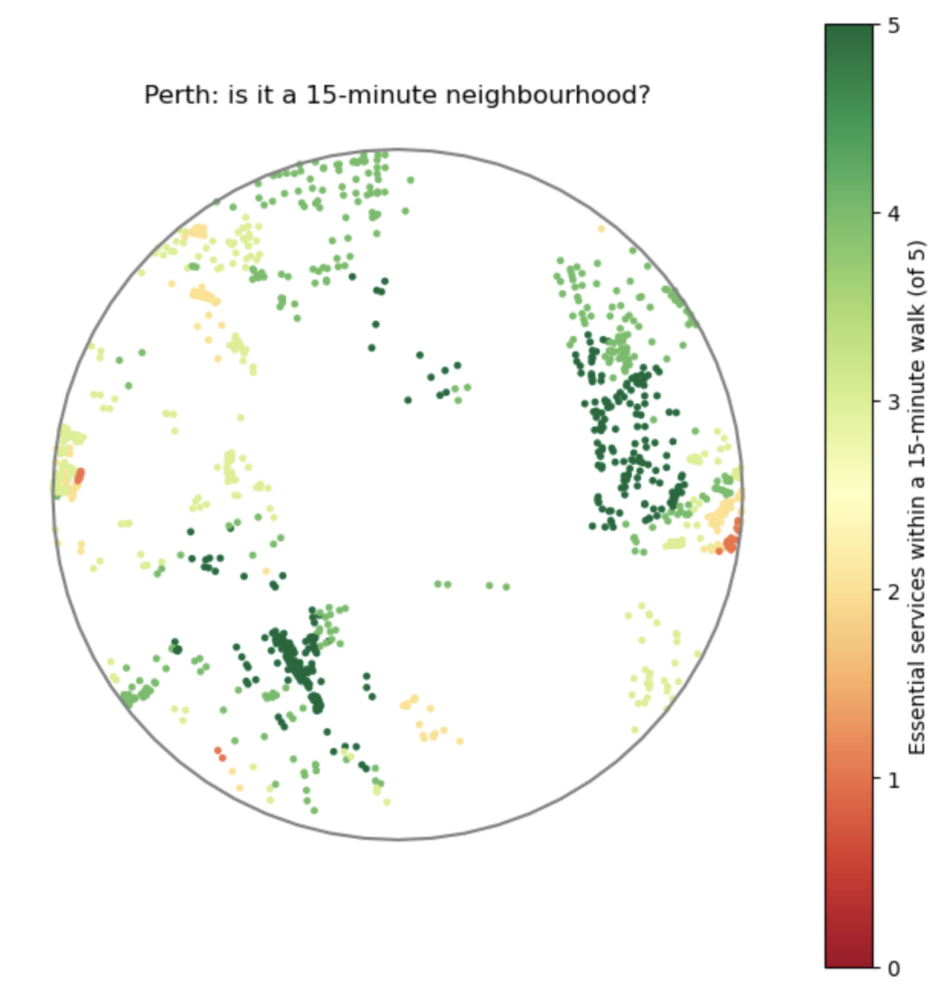

The number of services within a 10-min walk significantly decreased, except for public transport. Only 30% of residential junctions reach all 5 services on foot. In contrast, all residents can reach all the services via 10-min biking.

### Challenge 5

In [105]:
def isochrone(G, start_node, metres):
    reachable = nx.ego_graph(G, start_node, radius=metres, distance="length")
    streets = ox.graph_to_gdfs(reachable, nodes=False)
    return unary_union(list(streets.buffer(50)))

In [ ]:
food_shop = services[services["service"] == "Food shop"]
food_shop_nodes = set(ox.distance.nearest_nodes(G_walk, food_shop.geometry.x, food_shop.geometry.y))
dist_to_food_shop = nx.multi_source_dijkstra_path_length(G_walk, food_shop_nodes, cutoff=WALK_LIMIT, weight="length")

walk_edges = walk_edges.reset_index()
walk_edges["covered"] = walk_edges["u"].isin(set(dist_to_food_shop)) & walk_edges["v"].isin(set(dist_to_food_shop))

fig, ax = plt.subplots(figsize=(9, 9))
walk_edges[~walk_edges["covered"]].plot(ax=ax, color="lightgrey", linewidth=0.6)
walk_edges[walk_edges["covered"]].plot(ax=ax, color="#FFA500", linewidth=0.8)
food_shop.plot(ax=ax, color="black", markersize=10)
gpd.GeoSeries([neighbourhood], crs="EPSG:27700").boundary.plot(ax=ax, color="black", linewidth=1)
west, south, east, north = neighbourhood.buffer(WALK_LIMIT).bounds      # zoom to the neighbourhood
ax.set_xlim(west, east)
ax.set_ylim(south, north)
ax.set_title("Streets within a 15-minute walk of foodshop (orange); gaps in grey")
ax.set_axis_off()
plt.show()

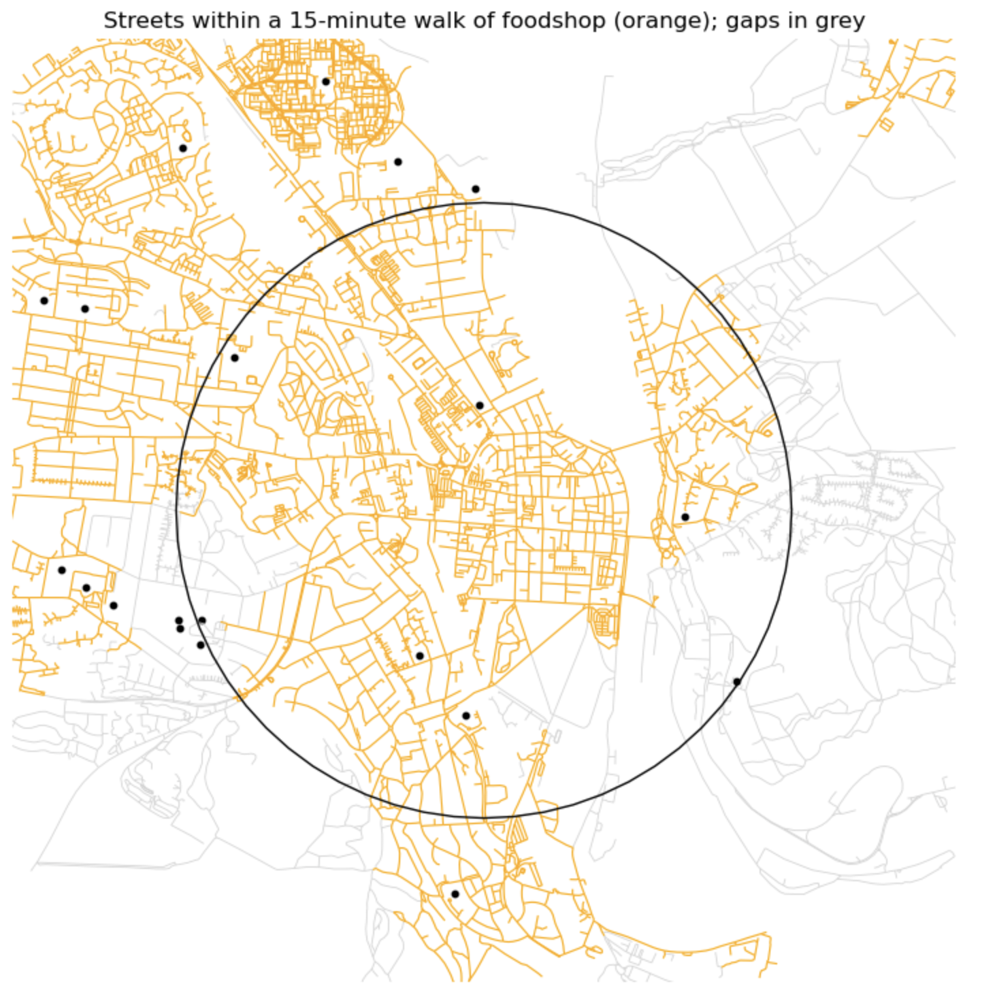

In [ ]:
school = services[services["service"] == "School"]
school_nodes = set(ox.distance.nearest_nodes(G_walk, school.geometry.x, school.geometry.y))
dist_to_school = nx.multi_source_dijkstra_path_length(G_walk, school_nodes, cutoff=WALK_LIMIT, weight="length")

walk_edges["covered"] = walk_edges["u"].isin(set(dist_to_school)) & walk_edges["v"].isin(set(dist_to_school))

fig, ax = plt.subplots(figsize=(9, 9))
walk_edges[~walk_edges["covered"]].plot(ax=ax, color="lightgrey", linewidth=0.6)
walk_edges[walk_edges["covered"]].plot(ax=ax, color="#00539B", linewidth=0.8)
school.plot(ax=ax, color="black", markersize=10)
gpd.GeoSeries([neighbourhood], crs="EPSG:27700").boundary.plot(ax=ax, color="black", linewidth=1)
west, south, east, north = neighbourhood.buffer(WALK_LIMIT).bounds      # zoom to the neighbourhood
ax.set_xlim(west, east)
ax.set_ylim(south, north)
ax.set_title("Streets within a 15-minute walk of school (blue); gaps in grey")
ax.set_axis_off()
plt.show()

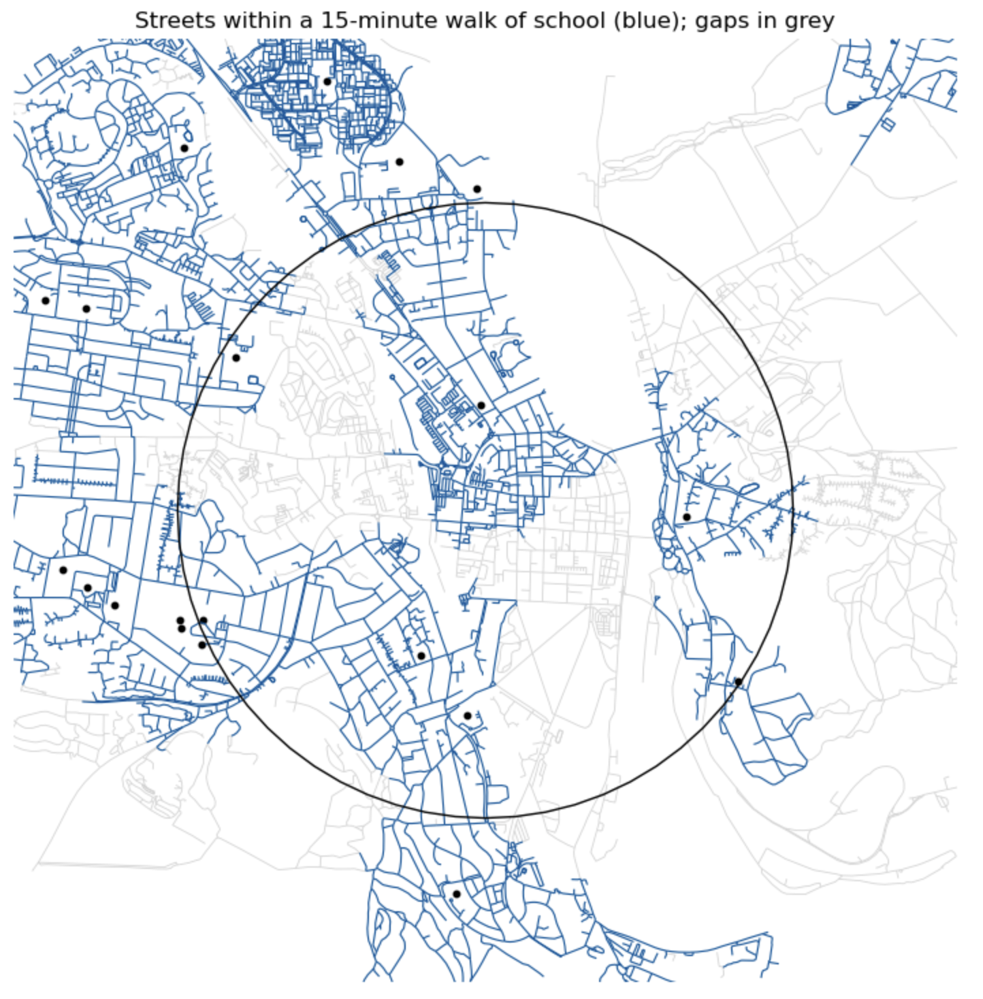

1. Healthcare: coverage is concentrated around the centre, with larger gaps towards the outer edges.
2. Food shops: the biggest gaps are towards the east and southeast, with smaller gaps in the southwest. Central and northern streets have extensive coverage.
3. Schools: gaps are more noticeable in the central-eastern street grid, parts of the west-central area, and the northeast. Some central streets covered by food shops are grey on the school map.

### Challenge 6

In [124]:
ox.settings.overpass_url = "https://overpass.private.coffee/api"

CITY = "Perth, Scotland"
CENTRE = (56.395, -3.431)  # failed with the city's name, so I replaced it with latitude and longitude
DIST = 2000              
CATCHMENT = 1200

G_city = ox.graph_from_point(CENTRE, dist=DIST, network_type="walk")
G_city = ox.project_graph(G_city).to_undirected()
crs = G_city.graph["crs"]

parks = ox.features_from_point(
    CENTRE, dist=DIST, tags={"leisure": "park"}
).to_crs(crs)

parks = parks[parks.geom_type.isin(["Polygon", "MultiPolygon"])].copy()
parks["area_m2"] = parks.area

buildings = ox.features_from_point(
    CENTRE, dist=DIST, tags={"building": True}
).to_crs(crs)

print(len(parks), "parks and", len(buildings), "buildings in", CITY)

/opt/homebrew/Caskroom/miniconda/base/envs/ua/lib/python3.10/site-packages/pandas/core/frame.py:721: DeprecationWarning: Passing a BlockManager to GeoDataFrame is deprecated and will raise in a future version. Use public APIs instead.
  warnings.warn(
/opt/homebrew/Caskroom/miniconda/base/envs/ua/lib/python3.10/site-packages/pandas/core/frame.py:721: DeprecationWarning: Passing a BlockManager to GeoDataFrame is deprecated and will raise in a future version. Use public APIs instead.
  warnings.warn(
/opt/homebrew/Caskroom/miniconda/base/envs/ua/lib/python3.10/site-packages/pandas/core/frame.py:721: DeprecationWarning: Passing a BlockManager to GeoDataFrame is deprecated and will raise in a future version. Use public APIs instead.
  warnings.warn(
/opt/homebrew/Caskroom/miniconda/base/envs/ua/lib/python3.10/site-packages/pandas/core/frame.py:721: DeprecationWarning: Passing a BlockManager to GeoDataFrame is deprecated and will raise in a future version. Use public APIs instead.
  warning

11 parks and 8588 buildings in Perth, Scotland


In [125]:
parks["node"] = ox.distance.nearest_nodes(
    G_city, parks.representative_point().x, parks.representative_point().y
)

buildings["node"] = ox.distance.nearest_nodes(
    G_city, buildings.representative_point().x, buildings.representative_point().y
)

demand = buildings["node"].value_counts()
demand.head()

/opt/homebrew/Caskroom/miniconda/base/envs/ua/lib/python3.10/site-packages/pandas/core/frame.py:721: DeprecationWarning: Passing a BlockManager to GeoDataFrame is deprecated and will raise in a future version. Use public APIs instead.
  warnings.warn(
/opt/homebrew/Caskroom/miniconda/base/envs/ua/lib/python3.10/site-packages/pandas/core/frame.py:721: DeprecationWarning: Passing a BlockManager to GeoDataFrame is deprecated and will raise in a future version. Use public APIs instead.
  warnings.warn(


node
569085517     39
568483559     35
7546347226    34
569645988     30
247084083     29
Name: count, dtype: int64

In [126]:
reach = {}
ratio = {}

for park_id, park in parks.iterrows():
    nearby = nx.single_source_dijkstra_path_length(
        G_city, park["node"], cutoff=CATCHMENT, weight="length"
    )

    buildings_nearby = sum(demand.get(node, 0) for node in nearby)

    reach[park_id] = nearby
    ratio[park_id] = (
        park["area_m2"] / buildings_nearby if buildings_nearby > 0 else 0
    )

parks["m2_per_building"] = pd.Series(ratio)

parks.sort_values("m2_per_building", ascending=False)[
    ["area_m2", "m2_per_building"]
].head(10).round(0)

/opt/homebrew/Caskroom/miniconda/base/envs/ua/lib/python3.10/site-packages/pandas/core/frame.py:721: DeprecationWarning: Passing a BlockManager to GeoDataFrame is deprecated and will raise in a future version. Use public APIs instead.
  warnings.warn(
/opt/homebrew/Caskroom/miniconda/base/envs/ua/lib/python3.10/site-packages/pandas/core/frame.py:721: DeprecationWarning: Passing a BlockManager to GeoDataFrame is deprecated and will raise in a future version. Use public APIs instead.
  warnings.warn(


area_m2  m2_per_building
element_type osmid                                
way          24240615    332585.0            381.0
             24240850     86169.0            115.0
             24240849    200546.0             94.0
             1343811967   17886.0             37.0
             428942335    29682.0             27.0
             59472869     23016.0             18.0
             1113440448   11859.0              7.0
             474420242     3584.0              7.0
             206851193     7403.0              3.0
             599395971     3226.0              2.0

/opt/homebrew/Caskroom/miniconda/base/envs/ua/lib/python3.10/site-packages/pandas/core/frame.py:721: DeprecationWarning: Passing a BlockManager to GeoDataFrame is deprecated and will raise in a future version. Use public APIs instead.
  warnings.warn(
/opt/homebrew/Caskroom/miniconda/base/envs/ua/lib/python3.10/site-packages/pandas/core/frame.py:721: DeprecationWarning: Passing a BlockManager to GeoDataFrame is deprecated and will raise in a future version. Use public APIs instead.
  warnings.warn(
/opt/homebrew/Caskroom/miniconda/base/envs/ua/lib/python3.10/site-packages/pandas/core/frame.py:721: DeprecationWarning: Passing a BlockManager to GeoDataFrame is deprecated and will raise in a future version. Use public APIs instead.
  warnings.warn(
/opt/homebrew/Caskroom/miniconda/base/envs/ua/lib/python3.10/site-packages/pandas/core/frame.py:721: DeprecationWarning: Passing a BlockManager to GeoDataFrame is deprecated and will raise in a future version. Use public APIs instead.
  warning

count    2423.0
mean       85.0
std       131.9
min         0.0
25%         0.2
50%        29.5
75%        97.7
max       616.1
Name: park_access, dtype: float64


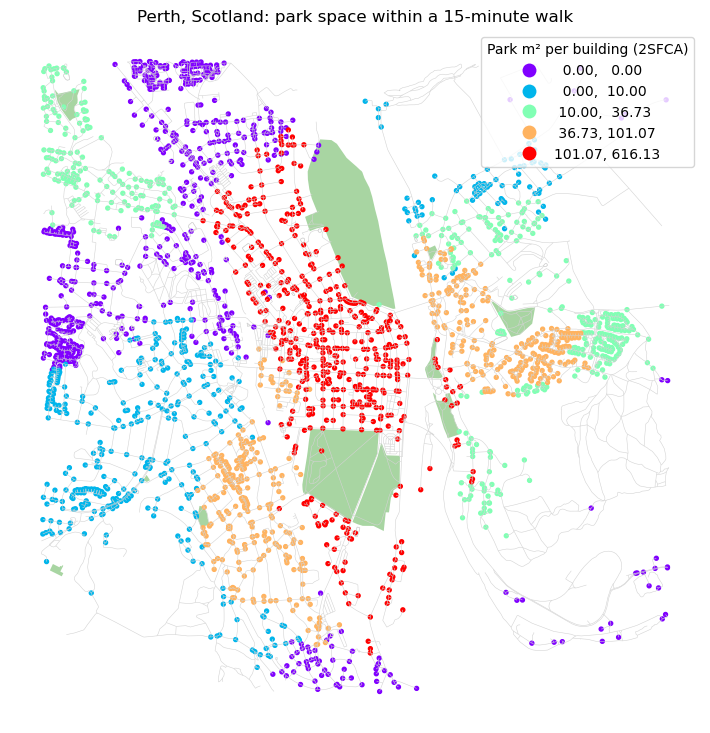

25.0% of building-associated junctions have a park access score of zero


In [127]:
city_nodes, city_edges = ox.graph_to_gdfs(G_city)
park_access = {node: 0.0 for node in G_city.nodes}

for park_id, nearby in reach.items():
    for node in nearby:
        park_access[node] += ratio[park_id]

city_nodes["park_access"] = pd.Series(park_access)

homes_city = city_nodes[city_nodes.index.isin(demand.index)]

print(homes_city["park_access"].describe().round(1))

fig, ax = plt.subplots(figsize=(9, 9))

city_edges.plot(ax=ax, color="lightgrey", linewidth=0.4)
parks.plot(ax=ax, color="#a8d5a2")

homes_city.sort_values("park_access").plot(
    ax=ax,
    column="park_access",
    cmap="rainbow",
    scheme="quantiles",
    k=5,
    markersize=8,
    legend=True,
    legend_kwds={
        "title": "Park m² per building (2SFCA)",
        "loc": "upper right"
    }
)

ax.set_title(f"{CITY}: park space within a 15-minute walk")
ax.set_axis_off()
plt.show()

print(
    f"{(homes_city['park_access'] == 0).mean():.1%} of building-associated "
    "junctions have a park access score of zero"
)

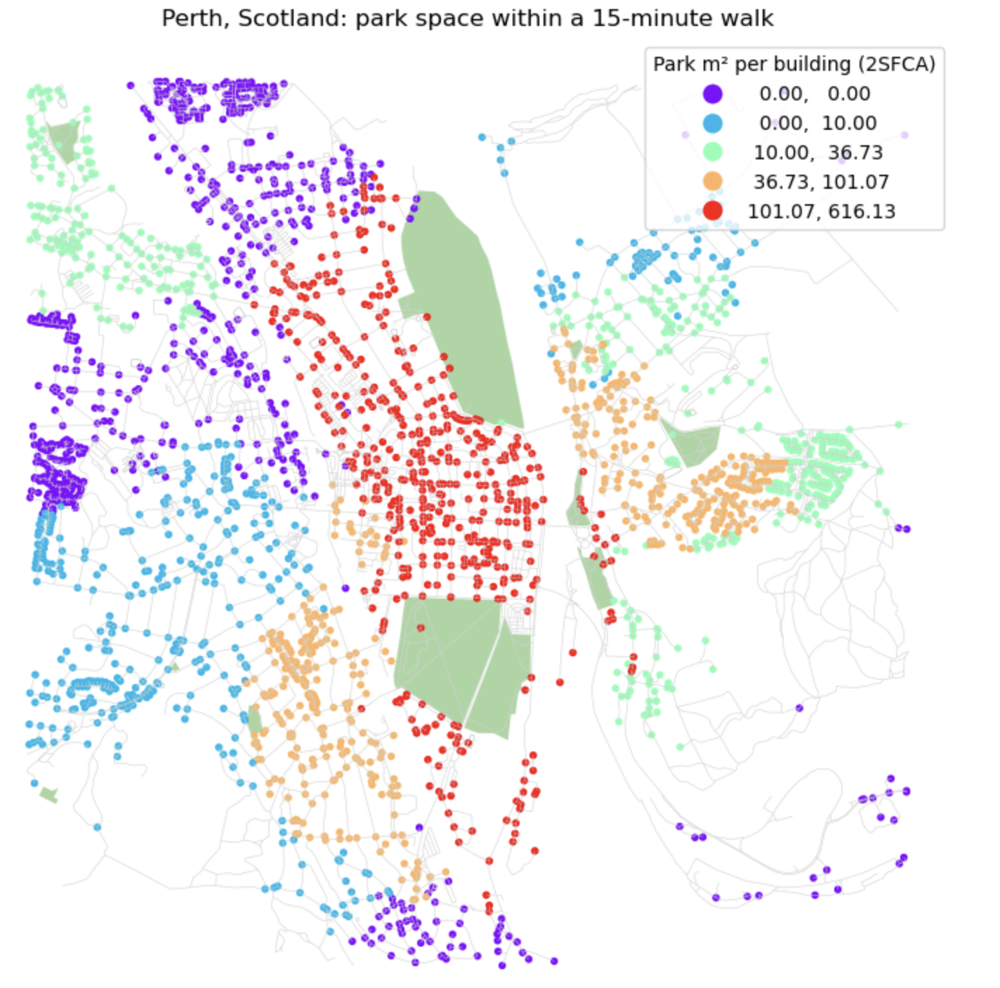

### Challenge 7

In [111]:
# Use the alternative Overpass server from your notebook to download OpenStreetMap data.
ox.settings.overpass_url = "https://overpass.private.coffee/api"

CITY = "De Pijp, Amsterdam"
CENTRE = (52.3540, 4.8930)
DIST = 2000
AREA = 800
WALK_SPEED = 80
CATCHMENT = 1200

# Downloads the walking network around the centre
G_city = ox.graph_from_point(CENTRE, dist=DIST, network_type="walk")
# Converts the network to a suitable local projected coordinate system
G_city = ox.project_graph(G_city).to_undirected()
crs = G_city.graph["crs"]

city_nodes, city_edges = ox.graph_to_gdfs(G_city)

# Creates a geographic point for the centre and projects it to match the network
centre = gpd.GeoSeries.from_xy(
    [CENTRE[1]], [CENTRE[0]], crs="EPSG:4326"
).to_crs(crs)

# Draws an 800 m radius circle around the centre
neighbourhood = centre.buffer(AREA).iloc[0]

# Downloads features tagged leisure=park around the centre
parks = ox.features_from_point(
    CENTRE, dist=DIST, tags={"leisure": "park"}
).to_crs(crs)

# Calculate the park's area for 2SFCA analysis later 
parks = parks[parks.geom_type.isin(["Polygon", "MultiPolygon"])].copy()
parks["area_m2"] = parks.area

# Downloads features with a building tag
buildings = ox.features_from_point(
    CENTRE, dist=DIST, tags={"building": True}
).to_crs(crs)

print(len(city_nodes), "junctions")
print(len(parks), "parks and", len(buildings), "buildings in", CITY)

/opt/homebrew/Caskroom/miniconda/base/envs/ua/lib/python3.10/site-packages/pandas/core/frame.py:721: DeprecationWarning: Passing a BlockManager to GeoDataFrame is deprecated and will raise in a future version. Use public APIs instead.
  warnings.warn(
/opt/homebrew/Caskroom/miniconda/base/envs/ua/lib/python3.10/site-packages/pandas/core/frame.py:721: DeprecationWarning: Passing a BlockManager to GeoDataFrame is deprecated and will raise in a future version. Use public APIs instead.
  warnings.warn(
/opt/homebrew/Caskroom/miniconda/base/envs/ua/lib/python3.10/site-packages/pandas/core/frame.py:721: DeprecationWarning: Passing a BlockManager to GeoDataFrame is deprecated and will raise in a future version. Use public APIs instead.
  warnings.warn(
/opt/homebrew/Caskroom/miniconda/base/envs/ua/lib/python3.10/site-packages/pandas/core/frame.py:721: DeprecationWarning: Passing a BlockManager to GeoDataFrame is deprecated and will raise in a future version. Use public APIs instead.
  warning

8400 junctions
69 parks and 35811 buildings in De Pijp, Amsterdam


/opt/homebrew/Caskroom/miniconda/base/envs/ua/lib/python3.10/site-packages/pandas/core/frame.py:721: DeprecationWarning: Passing a BlockManager to GeoDataFrame is deprecated and will raise in a future version. Use public APIs instead.
  warnings.warn(
/opt/homebrew/Caskroom/miniconda/base/envs/ua/lib/python3.10/site-packages/pandas/core/frame.py:721: DeprecationWarning: Passing a BlockManager to GeoDataFrame is deprecated and will raise in a future version. Use public APIs instead.
  warnings.warn(


In [112]:
# overture places in De Pijp
import overturemaps

BOX = gpd.GeoSeries(
    [centre.buffer(DIST).iloc[0]], crs=crs
).to_crs("EPSG:4326").total_bounds

# requests place categories
table = overturemaps.record_batch_reader(
    "place", bbox=BOX, stac=True
).read_all()

places = table.to_pandas()
places["geometry"] = gpd.GeoSeries.from_wkb(places["geometry"])
places = gpd.GeoDataFrame(
    places, geometry="geometry", crs="EPSG:4326"
).to_crs(crs)

# extract the places' main name
places["name"] = places["names"].str.get("primary")

print(len(places), "Overture places in", CITY)
places["basic_category"].value_counts()

26107 Overture places in De Pijp, Amsterdam


/opt/homebrew/Caskroom/miniconda/base/envs/ua/lib/python3.10/site-packages/pandas/core/frame.py:721: DeprecationWarning: Passing a BlockManager to GeoDataFrame is deprecated and will raise in a future version. Use public APIs instead.
  warnings.warn(


basic_category
restaurant                      2026
professional_service            1830
fashion_and_apparel_store       1400
personal_or_beauty_service      1077
corporate_or_business_office    1023
                                ... 
food_court                         1
pediatric_clinic                   1
sport_field                        1
atm                                1
military_base                      1
Name: count, Length: 228, dtype: int64

In [113]:
# extract food shops
is_food = places["basic_category"].str.contains(
    "food|grocery|supermarket|convenience|market|bakery|butcher", na=False
) # this time using a more extended category

# using the confidence level of 0.8
overture_shops = places[
    is_food & (places["confidence"] >= 0.8)
].copy()

# extract pharmacies
pharmacy = places["basic_category"].str.contains("pharmacy", na=False)

overture_pharmacy = places[
    pharmacy & (places["confidence"] >= 0.8)
].copy()

overture_shops["service"] = "Food shop"
overture_pharmacy["service"] = "Pharmacy"

SERVICES = ["Food shop", "Pharmacy"]

print(len(overture_shops), "food shops")
print(len(overture_pharmacy), "pharmacies")

371 food shops
58 pharmacies


/opt/homebrew/Caskroom/miniconda/base/envs/ua/lib/python3.10/site-packages/pandas/core/frame.py:721: DeprecationWarning: Passing a BlockManager to GeoDataFrame is deprecated and will raise in a future version. Use public APIs instead.
  warnings.warn(
/opt/homebrew/Caskroom/miniconda/base/envs/ua/lib/python3.10/site-packages/pandas/core/frame.py:721: DeprecationWarning: Passing a BlockManager to GeoDataFrame is deprecated and will raise in a future version. Use public APIs instead.
  warnings.warn(
/opt/homebrew/Caskroom/miniconda/base/envs/ua/lib/python3.10/site-packages/pandas/core/frame.py:721: DeprecationWarning: Passing a BlockManager to GeoDataFrame is deprecated and will raise in a future version. Use public APIs instead.
  warnings.warn(
/opt/homebrew/Caskroom/miniconda/base/envs/ua/lib/python3.10/site-packages/pandas/core/frame.py:721: DeprecationWarning: Passing a BlockManager to GeoDataFrame is deprecated and will raise in a future version. Use public APIs instead.
  warning

In [ ]:
# plot the isochrones for food shops
services = overture_shops
home = ox.distance.nearest_nodes(G_city, centre.x.iloc[0], centre.y.iloc[0])

fig, ax = plt.subplots(figsize=(9, 9))
city_edges.plot(ax=ax, color="lightgrey", linewidth=0.4)

for minutes, colour in [(15, "#cfe0f0"), (10, "#7fb0dd"), (5, "#00539B")]:
    shape = isochrone(G_city, home, minutes * WALK_SPEED)
    gpd.GeoSeries([shape], crs=crs).plot(ax=ax, color=colour, alpha=0.8)

iso15 = isochrone(G_city, home, 15 * WALK_SPEED)
inside = services[services.within(iso15)]

inside.plot(
    ax=ax, color="orange", markersize=25,
    label="Food shop", edgecolor="black", linewidth=0.3
)

ax.legend(loc="lower left")
ax.set_xlim(iso15.bounds[0] - 300, iso15.bounds[2] + 300)
ax.set_ylim(iso15.bounds[1] - 300, iso15.bounds[3] + 300)
ax.set_title("De Pijp: 5, 10 and 15-minute walks, with food shops inside")
ax.set_axis_off()
plt.show()

print(inside["service"].value_counts())

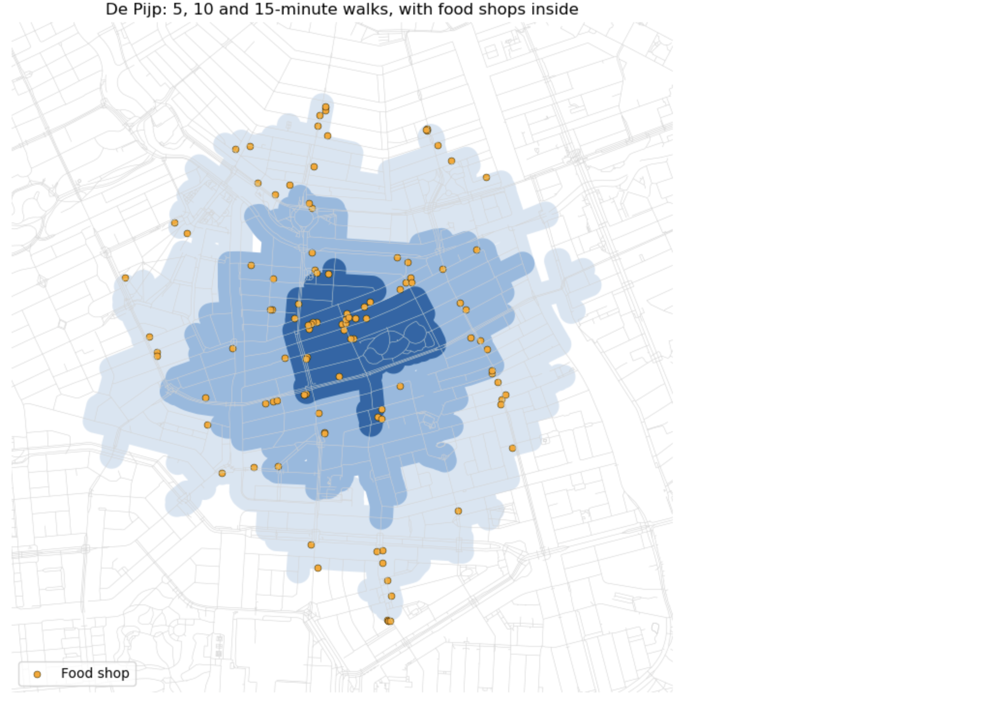

In [ ]:
# plot the isochrone for pharmacy
services = overture_pharmacy
home = ox.distance.nearest_nodes(G_city, centre.x.iloc[0], centre.y.iloc[0])

fig, ax = plt.subplots(figsize=(9, 9))
city_edges.plot(ax=ax, color="lightgrey", linewidth=0.4)

for minutes, colour in [(15, "#cfe0f0"), (10, "#7fb0dd"), (5, "#00539B")]:
    shape = isochrone(G_city, home, minutes * WALK_SPEED)
    gpd.GeoSeries([shape], crs=crs).plot(ax=ax, color=colour, alpha=0.8)

iso15 = isochrone(G_city, home, 15 * WALK_SPEED)
inside = services[services.within(iso15)]

inside.plot(
    ax=ax, color="purple", markersize=25,
    label="Pharmacy", edgecolor="black", linewidth=0.3
)

ax.legend(loc="lower left")
ax.set_xlim(iso15.bounds[0] - 300, iso15.bounds[2] + 300)
ax.set_ylim(iso15.bounds[1] - 300, iso15.bounds[3] + 300)
ax.set_title("De Pijp: 5, 10 and 15-minute walks, with pharmacies inside")
ax.set_axis_off()
plt.show()

print(inside["service"].value_counts())

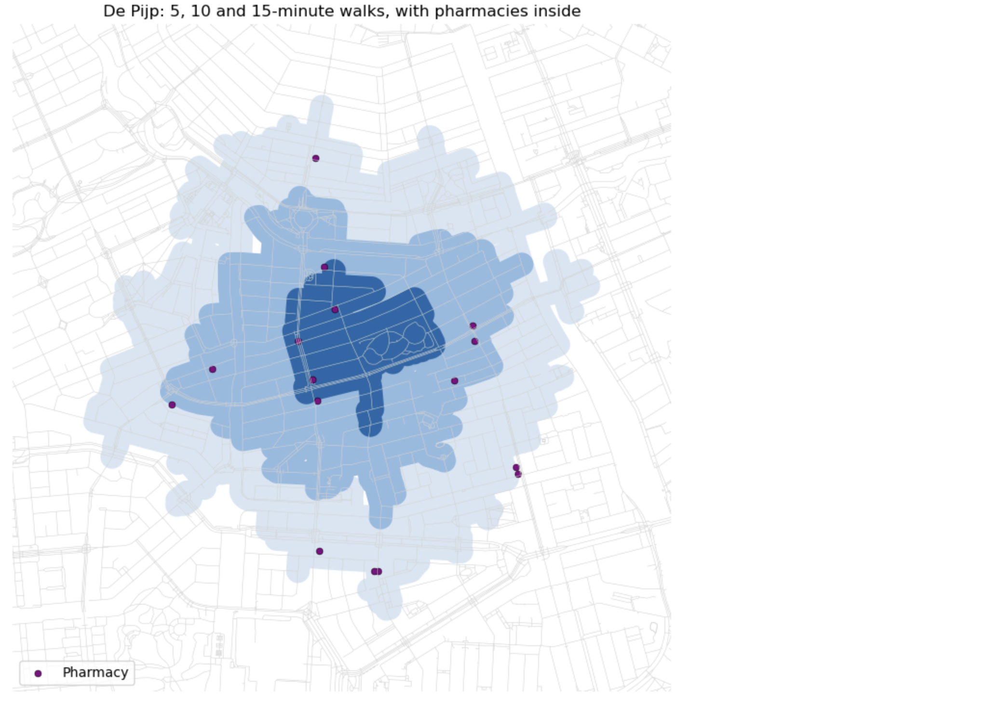

In [116]:
# attach parks and buildings to junctions
parks["node"] = ox.distance.nearest_nodes(
    G_city,
    parks.representative_point().x,
    parks.representative_point().y
)

buildings["node"] = ox.distance.nearest_nodes(
    G_city,
    buildings.representative_point().x,
    buildings.representative_point().y
)

demand = buildings["node"].value_counts()
demand.head()

/opt/homebrew/Caskroom/miniconda/base/envs/ua/lib/python3.10/site-packages/pandas/core/frame.py:721: DeprecationWarning: Passing a BlockManager to GeoDataFrame is deprecated and will raise in a future version. Use public APIs instead.
  warnings.warn(
/opt/homebrew/Caskroom/miniconda/base/envs/ua/lib/python3.10/site-packages/pandas/core/frame.py:721: DeprecationWarning: Passing a BlockManager to GeoDataFrame is deprecated and will raise in a future version. Use public APIs instead.
  warnings.warn(


node
11310629118    113
46319842       108
46343002        87
46343839        81
11832584550     77
Name: count, dtype: int64

In [117]:
# calculate the park ratios
reach = {}
ratio = {}

for park_id, park in parks.iterrows():
    nearby = nx.single_source_dijkstra_path_length(
        G_city, park["node"],
        cutoff=CATCHMENT, weight="length"
    )

    buildings_nearby = sum(demand.get(node, 0) for node in nearby)

    reach[park_id] = nearby
    ratio[park_id] = (
        park["area_m2"] / buildings_nearby
        if buildings_nearby > 0 else 0
    )

parks["m2_per_building"] = pd.Series(ratio)

parks.sort_values(
    "m2_per_building", ascending=False
)[["name", "area_m2", "m2_per_building"]].head(10).round(0)

/opt/homebrew/Caskroom/miniconda/base/envs/ua/lib/python3.10/site-packages/pandas/core/frame.py:721: DeprecationWarning: Passing a BlockManager to GeoDataFrame is deprecated and will raise in a future version. Use public APIs instead.
  warnings.warn(
/opt/homebrew/Caskroom/miniconda/base/envs/ua/lib/python3.10/site-packages/pandas/core/frame.py:721: DeprecationWarning: Passing a BlockManager to GeoDataFrame is deprecated and will raise in a future version. Use public APIs instead.
  warnings.warn(


name   area_m2  m2_per_building
element_type osmid                                                        
relation     17080648                Vondelpark  476887.0            154.0
way          26037982               Beatrixpark  232405.0             81.0
             4366722                 Oosterpark  143632.0             50.0
             897155293          Bella Vistapark   22178.0             45.0
             1344387596          Park Somerlust   17968.0             34.0
             1540708357                     NaN    2615.0             34.0
             21592446    Martin Luther Kingpark   44407.0             11.0
             1268819095  Martin Luther Kingpark   31369.0              8.0
             399509800             Touwbaanpark    2503.0              7.0
             25965389               Museumplein   37269.0              5.0

In [118]:
# Calculate access for homes within 800 m
park_access = {node: 0.0 for node in G_city.nodes}

for park_id, nearby in reach.items():
    for node in nearby:
        park_access[node] += ratio[park_id]

city_nodes["park_access"] = pd.Series(park_access)

homes_city = city_nodes[
    city_nodes.index.isin(demand.index)
    & city_nodes.within(neighbourhood)
].copy()

print(len(homes_city), "building-associated junctions within 800 m")
homes_city["park_access"].describe().round(0)

469 building-associated junctions within 800 m


/opt/homebrew/Caskroom/miniconda/base/envs/ua/lib/python3.10/site-packages/pandas/core/frame.py:721: DeprecationWarning: Passing a BlockManager to GeoDataFrame is deprecated and will raise in a future version. Use public APIs instead.
  warnings.warn(
/opt/homebrew/Caskroom/miniconda/base/envs/ua/lib/python3.10/site-packages/pandas/core/frame.py:721: DeprecationWarning: Passing a BlockManager to GeoDataFrame is deprecated and will raise in a future version. Use public APIs instead.
  warnings.warn(


count    469.0
mean      15.0
std       15.0
min        0.0
25%        8.0
50%       13.0
75%       16.0
max       96.0
Name: park_access, dtype: float64

In [ ]:
# Map park access
fig, ax = plt.subplots(figsize=(9, 9))

city_edges.plot(ax=ax, color="lightgrey", linewidth=0.4)
parks.plot(ax=ax, color="#a8d5a2")

homes_city.sort_values("park_access").plot(
    ax=ax, column="park_access", cmap="rainbow",
    scheme="quantiles", k=5, markersize=8, legend=True,
    legend_kwds={"title": "Park m² per building (2SFCA)", "loc": "upper right"}
)

ax.set_title(f"{CITY}: park space within a 15-minute walk, shared with neighbours")
ax.set_axis_off()
plt.show()

print(f"{(homes_city['park_access'] == 0).mean():.0%} of home junctions have no park within a 15-minute walk")

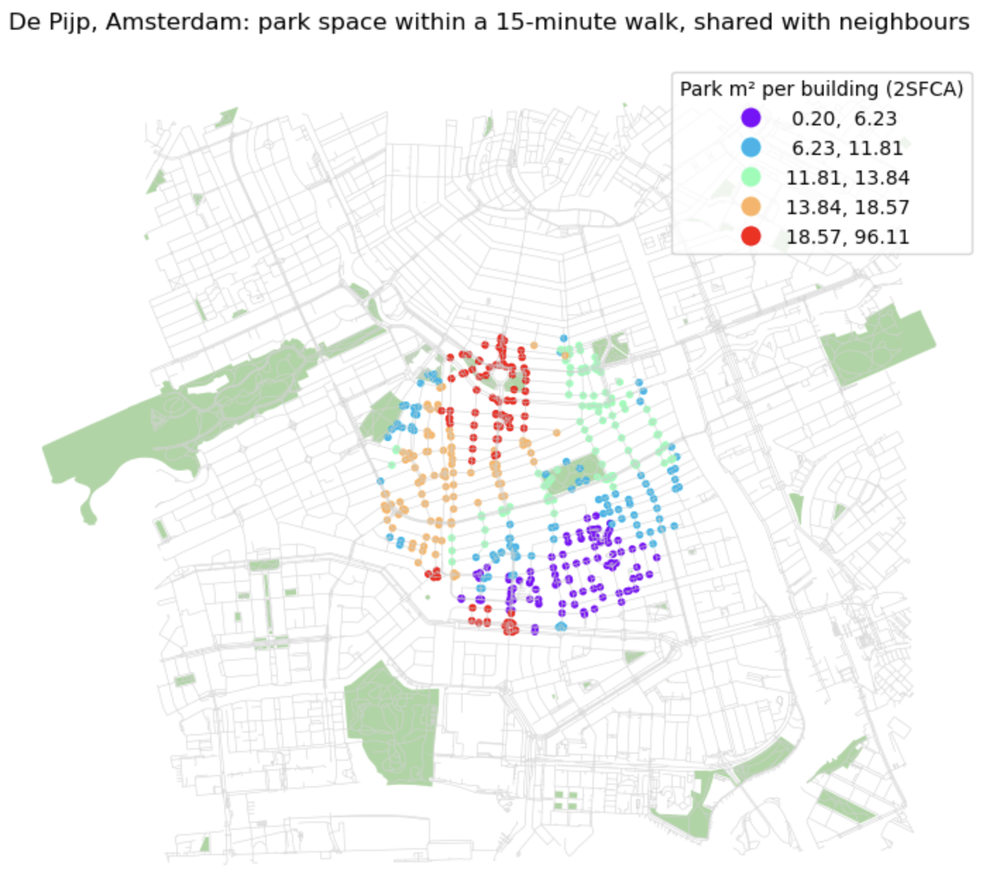

In [120]:
# Creating the summary table
summary = pd.DataFrame({
    "Value": [
        len(parks),
        len(buildings),
        len(homes_city),
        homes_city["park_access"].median(),
        (homes_city["park_access"] == 0).mean() * 100,
        len(overture_shops[overture_shops.within(iso15)]),
        len(overture_pharmacy[overture_pharmacy.within(iso15)])
    ]
}, index=[
    "Parks in download area",
    "Buildings in download area",
    "Home junctions within 800 m",
    "Median park m² per building",
    "% home junctions with no park within 15 minutes",
    "Food shops within 15 minutes of centre",
    "Pharmacies within 15 minutes of centre"
])

summary.round(1)

/opt/homebrew/Caskroom/miniconda/base/envs/ua/lib/python3.10/site-packages/pandas/core/frame.py:721: DeprecationWarning: Passing a BlockManager to GeoDataFrame is deprecated and will raise in a future version. Use public APIs instead.
  warnings.warn(
/opt/homebrew/Caskroom/miniconda/base/envs/ua/lib/python3.10/site-packages/pandas/core/frame.py:721: DeprecationWarning: Passing a BlockManager to GeoDataFrame is deprecated and will raise in a future version. Use public APIs instead.
  warnings.warn(


,Value
Parks in download area,69.0
Buildings in download area,35811.0
Home junctions within 800 m,469.0
Median park m² per building,13.1
% home junctions with no park within 15 minutes,0.0
Food shops within 15 minutes of centre,109.0
Pharmacies within 15 minutes of centre,16.0


De Pijp broadly meets the 15-minute neighbourhood concept for the services assessed. The centre’s estimated 15-minute walking catchment contains 109 food shops and 16 pharmacies, indicating substantial choices. All 469 building-associated home junctions within 800 m have modelled access to at least one park, with a median 2SFCA score of 13.1 m² per building. However, park access is uneven: northern junctions generally have higher scores, while southeastern junctions have lower scores, suggesting less park space relative to surrounding demand. 

The limitation of the analysis lies in buildings not being differentiated. Houses, apartment and offices receive equal weight, which may underestimate demand in densely populated residential buildings especially student dormitory and overestimate residential demand in office areas. 

## Lab No 6 - Geodemographics

**Main goal**: The aim of this classification is to group Birmingham’s Output Areas with similar demographic, household, employment and health characteristics to support local service planning. 

1. Census data accessed via: https://www.nomisweb.co.uk/sources/census_2021_bulk
2. Output area shapefile accessed via: https://data.geods.ac.uk/dataset/output-area-classification-2021

In [1]:
import os
import pandas as pd
import geopandas as gpd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA

RANDOM_SEED = 42

In [2]:
# Merge the CSV files focusing on four topics
csv_directory = "Assignment2_data/2021_census"

csv_files = [
    file for file in os.listdir(csv_directory)
    if file.endswith(".csv")
    and file != "merged_census_data.csv"
]

merged_data = pd.DataFrame()

for csv_file in csv_files:
    csv_path = os.path.join(csv_directory, csv_file)
    df_csv = pd.read_csv(csv_path, low_memory=False)

    merged_data = pd.concat([merged_data, df_csv], axis=1)

merged_data.to_csv(
    "Assignment2_data/2021_census/merged_census_data.csv",
    index=False
)

merged_data.head()

,date,geography,geography code,Household composition: Total; measures: Value,Household composition: One person household; measures: Value,Household composition: One person household: Aged 66 years and over; measures: Value,Household composition: One person household: Other; measures: Value,Household composition: Single family household; measures: Value,Household composition: Single family household: All aged 66 years and over; measures: Value,Household composition: Single family household: Married or civil partnership couple; measures: Value,...,Economic activity status: Economically active and a full-time student:In employment:Self-employed without employees,Economic activity status: Economically active and a full-time student: In employment: Self-employed without employees: Part-time,Economic activity status: Economically active and a full-time student: In employment: Self-employed without employees: Full-time,Economic activity status: Economically active and a full-time student: Unemployed,Economic activity status: Economically inactive,Economic activity status: Economically inactive: Retired,Economic activity status: Economically inactive: Student,Economic activity status: Economically inactive: Looking after home or family,Economic activity status: Economically inactive: Long-term sick or disabled,Economic activity status: Economically inactive: Other
0,2021,E00060274,E00060274,114,29,10,19,80,7,22,...,0,0,0,0,63,52,5,2,1,3
1,2021,E00060275,E00060275,160,35,15,20,116,10,38,...,0,0,0,0,83,57,19,6,0,1
2,2021,E00060276,E00060276,117,35,24,11,81,18,33,...,0,0,0,0,36,23,3,3,1,6
3,2021,E00060277,E00060277,122,41,12,29,81,7,31,...,0,0,0,0,32,17,11,1,1,2
4,2021,E00060279,E00060279,119,34,11,23,80,12,29,...,1,0,1,0,41,15,8,0,9,9


In [3]:
# Load the output (OA) area shapefile for the entire England and Wales
gdf = gpd.read_file("Assignment2_data/oac21/oac21.shp")

print(gdf.shape)
print(gdf.columns.tolist())

gdf.head()

(239023, 7)
['GeographyC', 'LAD25Code', 'LAD25Name', 'Supergroup', 'Group', 'Subgroup', 'geometry']


,GeographyC,LAD25Code,LAD25Name,Supergroup,Group,Subgroup,geometry
0,E00000001,E09000001,City of London,3,3c,3c2,"POLYGON ((532303.492 181814.110, 532213.378 18..."
1,E00000003,E09000001,City of London,3,3c,3c2,"POLYGON ((532213.378 181846.192, 532190.539 18..."
2,E00000005,E09000001,City of London,3,3c,3c1,"POLYGON ((532180.131 181763.020, 532219.161 18..."
3,E00000007,E09000001,City of London,3,3c,3c1,"POLYGON ((532201.292 181668.180, 532267.728 18..."
4,E00000010,E09000001,City of London,3,3b,3b1,"POLYGON ((532127.958 182133.192, 532089.264 18..."


In [4]:
# I want to study the city of Birmingham, so keep only the Birmingham area
birmingham_oa = gdf[gdf["LAD25Name"] == "Birmingham"].copy()

print("Birmingham Output Areas:", len(birmingham_oa))

birmingham_oa.head()

Birmingham Output Areas: 3325


,GeographyC,LAD25Code,LAD25Name,Supergroup,Group,Subgroup,geometry
42441,E00045077,E08000025,Birmingham,5,5b,5b1,"POLYGON ((413029.927 284180.623, 413027.829 28..."
42442,E00045078,E08000025,Birmingham,5,5b,5b2,"POLYGON ((413018.737 283913.107, 412949.765 28..."
42443,E00045079,E08000025,Birmingham,4,4a,4a3,"POLYGON ((412209.000 283476.000, 412210.000 28..."
42444,E00045080,E08000025,Birmingham,5,5b,5b1,"POLYGON ((411823.000 283951.001, 411804.000 28..."
42445,E00045081,E08000025,Birmingham,4,4a,4a1,"POLYGON ((411850.242 283487.840, 411902.304 28..."


<Axes: >

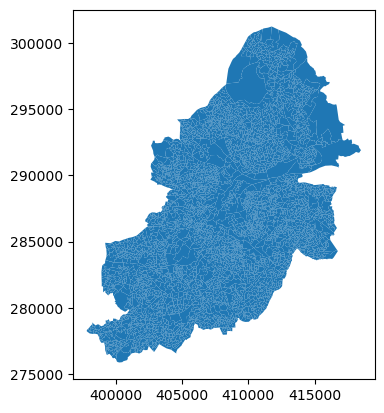

In [5]:
# Check the boundaries
birmingham_oa.plot()

In [6]:
# Clear the duplicated geography code columns
csv_data = merged_data.loc[
    :, ~merged_data.columns.duplicated()
].copy()

In [7]:
# Join the Birmingham city boundary with the demographic data
birmingham_census_data = birmingham_oa.merge(
    csv_data,
    left_on="GeographyC",
    right_on="geography code",
    how="left"
)

birmingham_census_data.head()

,GeographyC,LAD25Code,LAD25Name,Supergroup,Group,Subgroup,geometry,date,geography,geography code,...,Economic activity status: Economically active and a full-time student:In employment:Self-employed without employees,Economic activity status: Economically active and a full-time student: In employment: Self-employed without employees: Part-time,Economic activity status: Economically active and a full-time student: In employment: Self-employed without employees: Full-time,Economic activity status: Economically active and a full-time student: Unemployed,Economic activity status: Economically inactive,Economic activity status: Economically inactive: Retired,Economic activity status: Economically inactive: Student,Economic activity status: Economically inactive: Looking after home or family,Economic activity status: Economically inactive: Long-term sick or disabled,Economic activity status: Economically inactive: Other
0,E00045077,E08000025,Birmingham,5,5b,5b1,"POLYGON ((413029.927 284180.623, 413027.829 28...",2021,E00045077,E00045077,...,2,2,0,3,101,25,27,24,13,12
1,E00045078,E08000025,Birmingham,5,5b,5b2,"POLYGON ((413018.737 283913.107, 412949.765 28...",2021,E00045078,E00045078,...,1,1,0,0,46,20,9,8,3,6
2,E00045079,E08000025,Birmingham,4,4a,4a3,"POLYGON ((412209.000 283476.000, 412210.000 28...",2021,E00045079,E00045079,...,0,0,0,1,119,50,15,21,15,18
3,E00045080,E08000025,Birmingham,5,5b,5b1,"POLYGON ((411823.000 283951.001, 411804.000 28...",2021,E00045080,E00045080,...,0,0,0,0,87,31,12,18,20,6
4,E00045081,E08000025,Birmingham,4,4a,4a1,"POLYGON ((411850.242 283487.840, 411902.304 28...",2021,E00045081,E00045081,...,0,0,0,0,122,78,10,12,12,10


In [8]:
# Check whether there is unmatched OAs
print("Birmingham OAs:", len(birmingham_census_data))

print(
    "OAs without a census match:",
    birmingham_census_data["geography code"].isna().sum()
)

Birmingham OAs: 3325
OAs without a census match: 0


In [9]:
# Check the columns
birmingham_census_data.columns.tolist()

['GeographyC',
 'LAD25Code',
 'LAD25Name',
 'Supergroup',
 'Group',
 'Subgroup',
 'geometry',
 'date',
 'geography',
 'geography code',
 'Household composition: Total; measures: Value',
 'Household composition: One person household; measures: Value',
 'Household composition: One person household: Aged 66 years and over; measures: Value',
 'Household composition: One person household: Other; measures: Value',
 'Household composition: Single family household; measures: Value',
 'Household composition: Single family household: All aged 66 years and over; measures: Value',
 'Household composition: Single family household: Married or civil partnership couple; measures: Value',
 'Household composition: Single family household: Married or civil partnership couple: No children; measures: Value',
 'Household composition: Single family household: Married or civil partnership couple: Dependent children; measures: Value',
 'Household composition: Single family household: Married or civil partnersh

In [10]:
# Subset the interesting variables and calculate the percentage 
data = birmingham_census_data

# Age
age_total = data["Age: Total"]

age_0_14 = (
    data["Age: Aged 4 years and under"]
    + data["Age: Aged 5 to 9 years"]
    + data["Age: Aged 10 to 14 years"]
)

age_20_34 = (
    data["Age: Aged 20 to 24 years"]
    + data["Age: Aged 25 to 29 years"]
    + data["Age: Aged 30 to 34 years"]
)

age_75_plus = (
    data["Age: Aged 75 to 79 years"]
    + data["Age: Aged 80 to 84 years"]
    + data["Age: Aged 85 years and over"]
)

# Household composition
household = "Household composition: Total; measures: Value"
household_total = data[household]

older_living_alone = data[
    "Household composition: One person household: Aged 66 years and over; measures: Value"
]

other_living_alone = data[
    "Household composition: One person household: Other; measures: Value"
]

lone_parent = data[
    "Household composition: Single family household: Lone parent family: With dependent children; measures: Value"
]

# Economic activity
adult_total = data[
    "Economic activity status: Total: All usual residents aged 16 years and over"
]

active_total = (
    data["Economic activity status: Economically active (excluding full-time students)"]
    + data["Economic activity status: Economically active and a full-time student"]
)

unemployed = (
    data["Economic activity status: Economically active (excluding full-time students): Unemployed"]
    + data["Economic activity status: Economically active and a full-time student: Unemployed"]
)

looking_after_family = data[
    "Economic activity status: Economically inactive: Looking after home or family"
]

long_term_sick = data[
    "Economic activity status: Economically inactive: Long-term sick or disabled"
]

# General health
health_total = data["General health: Total: All usual residents"]

poor_health = (
    data["General health: Bad health"]
    + data["General health: Very bad health"]
)

# Convert counts into percentages for each Output Area
result_dataframe = pd.DataFrame({
    "Age_0_14": age_0_14 / age_total * 100,
    "Age_20_34": age_20_34 / age_total * 100,
    "Age_75_plus": age_75_plus / age_total * 100,
    "Older_Living_Alone": older_living_alone / household_total * 100,
    "Other_Living_Alone": other_living_alone / household_total * 100,
    "Lone_Parent_Dependent_Children": lone_parent / household_total * 100,
    "Unemployment_Rate": unemployed / active_total * 100,
    "Inactive_Looking_After_Family": looking_after_family / adult_total * 100,
    "Inactive_Long_Term_Sick_Disabled": long_term_sick / adult_total * 100,
    "Fair_Health": data["General health: Fair health"] / health_total * 100,
    "Bad_Or_Very_Bad_Health": poor_health / health_total * 100
})

# If the denominator (total population) is zero, the division will produce inf values, so replace them with NaN
result_dataframe = result_dataframe.replace([np.inf, -np.inf], np.nan)

input_vars = result_dataframe.columns.tolist()

result_dataframe.head()

,Age_0_14,Age_20_34,Age_75_plus,Older_Living_Alone,Other_Living_Alone,Lone_Parent_Dependent_Children,Unemployment_Rate,Inactive_Looking_After_Family,Inactive_Long_Term_Sick_Disabled,Fair_Health,Bad_Or_Very_Bad_Health
0,20.086393,31.749460,3.455724,5.217391,14.782609,1.739130,3.816794,6.611570,3.581267,8.242950,4.121475
1,21.694915,18.644068,3.050847,11.333333,15.333333,7.333333,4.519774,3.587444,1.345291,9.152542,1.694915
2,23.779193,24.840764,5.520170,22.151899,31.645570,7.594937,6.224066,5.833333,4.166667,15.074310,5.944798
3,23.129252,18.707483,7.482993,18.248175,15.328467,5.839416,10.370370,8.108108,9.009009,19.727891,4.761905
4,17.759563,18.032787,14.754098,30.693069,24.752475,4.950495,4.597701,4.054054,4.054054,12.295082,4.371585


In [11]:
# DEA
result_dataframe.describe()

,Age_0_14,Age_20_34,Age_75_plus,Older_Living_Alone,Other_Living_Alone,Lone_Parent_Dependent_Children,Unemployment_Rate,Inactive_Looking_After_Family,Inactive_Long_Term_Sick_Disabled,Fair_Health,Bad_Or_Very_Bad_Health
count,3325.000000,3325.000000,3325.000000,3325.000000,3325.000000,3325.000000,3325.000000,3325.000000,3325.000000,3325.000000,3325.000000
mean,18.717149,18.194014,7.630237,10.980424,19.659194,9.650953,5.320139,5.047669,3.015503,11.427416,4.055596
std,4.884554,6.905255,5.069871,7.465824,12.000368,6.830614,2.960198,2.447225,2.738149,3.563401,2.497634
min,0.735294,1.785714,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,3.083700,0.000000
25%,15.384615,13.537118,3.921569,6.293706,11.450382,4.545455,3.296703,3.363914,1.195219,8.996540,2.395210
50%,18.620690,17.507418,6.628242,9.734513,17.037037,8.474576,4.861111,4.577465,2.371542,11.111111,3.592814
75%,21.639344,21.283784,10.064935,13.953488,24.603175,13.223140,6.827309,6.250000,4.072398,13.437500,5.135135
max,48.511905,65.272727,43.859649,78.571429,85.977860,63.846154,28.571429,23.699422,24.475524,37.719298,26.315789


/opt/homebrew/Caskroom/miniconda/base/envs/ua/lib/python3.10/site-packages/seaborn/_base.py:948: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  data_subset = grouped_data.get_group(pd_key)
/opt/homebrew/Caskroom/miniconda/base/envs/ua/lib/python3.10/site-packages/seaborn/_base.py:948: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  data_subset = grouped_data.get_group(pd_key)
/opt/homebrew/Caskroom/miniconda/base/envs/ua/lib/python3.10/site-packages/seaborn/_base.py:948: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  data_subset = grouped_

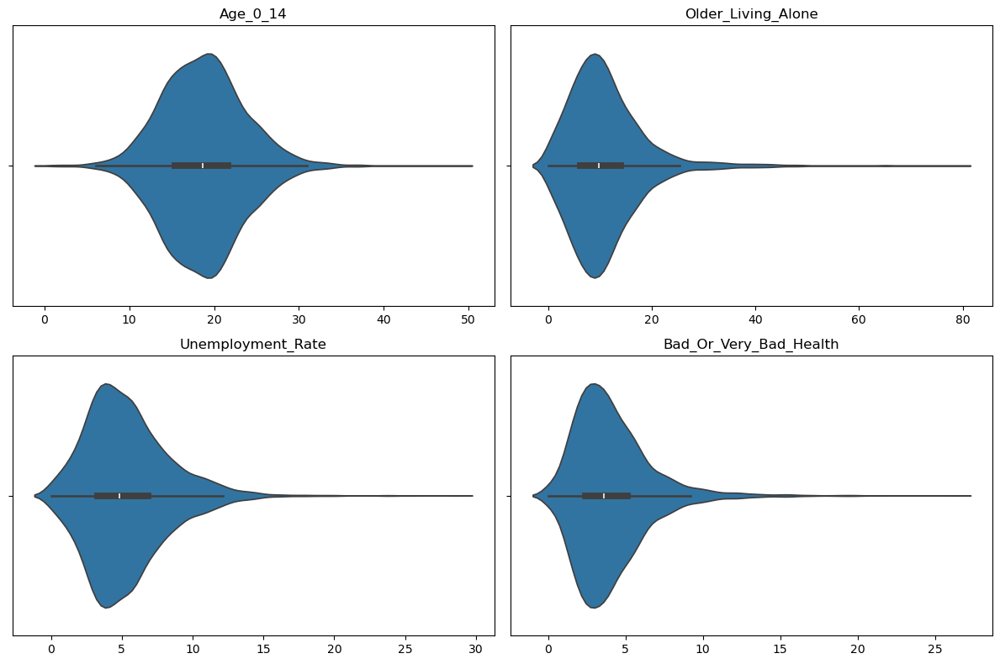

In [12]:
import seaborn as sns
import matplotlib.pyplot as plt

attributes_to_plot = [
    "Age_0_14",
    "Older_Living_Alone",
    "Unemployment_Rate",
    "Bad_Or_Very_Bad_Health"
]

plt.figure(figsize=(12, 8))

for i, attribute in enumerate(attributes_to_plot, 1):
    plt.subplot(2, 2, i)
    sns.violinplot(x=result_dataframe[attribute])
    plt.title(attribute)
    plt.xlabel("")
    plt.ylabel("")

plt.tight_layout()
plt.show()

**DEA**: the "Older_Living_Alone" is heavily right-skewed. Checking the results I found out that the percentage was derived from a sample of more than 100 households, therefore, they are valid results and shall be retained. Nevertheless, the right-skewed variable can make K-means split off a few unusually high Output Areas, while putting many areas with low or moderate values into the same cluster.

In [13]:
# Check whether the outliers were because of incomplete data
older_check = pd.DataFrame({
    "GeographyC": birmingham_census_data["GeographyC"],
    "Older one-person households": older_living_alone,
    "Total households": household_total,
    "Percentage": result_dataframe["Older_Living_Alone"]
})

older_check.sort_values("Percentage", ascending=False).head()

,GeographyC,Older one-person households,Total households,Percentage
3123,E00186118,154,196,78.571429
3309,E00186304,167,229,72.925764
2463,E00047708,70,106,66.037736
3286,E00186281,160,243,65.843621
3012,E00175703,173,269,64.312268


In [14]:
# Concatenate the result dataframe with the output area code and geometry
birmingham_results = pd.concat(
    [
        birmingham_census_data[["GeographyC", "geometry"]],
        result_dataframe
    ],
    axis=1
)

birmingham_results.head()

,GeographyC,geometry,Age_0_14,Age_20_34,Age_75_plus,Older_Living_Alone,Other_Living_Alone,Lone_Parent_Dependent_Children,Unemployment_Rate,Inactive_Looking_After_Family,Inactive_Long_Term_Sick_Disabled,Fair_Health,Bad_Or_Very_Bad_Health
0,E00045077,"POLYGON ((413029.927 284180.623, 413027.829 28...",20.086393,31.749460,3.455724,5.217391,14.782609,1.739130,3.816794,6.611570,3.581267,8.242950,4.121475
1,E00045078,"POLYGON ((413018.737 283913.107, 412949.765 28...",21.694915,18.644068,3.050847,11.333333,15.333333,7.333333,4.519774,3.587444,1.345291,9.152542,1.694915
2,E00045079,"POLYGON ((412209.000 283476.000, 412210.000 28...",23.779193,24.840764,5.520170,22.151899,31.645570,7.594937,6.224066,5.833333,4.166667,15.074310,5.944798
3,E00045080,"POLYGON ((411823.000 283951.001, 411804.000 28...",23.129252,18.707483,7.482993,18.248175,15.328467,5.839416,10.370370,8.108108,9.009009,19.727891,4.761905
4,E00045081,"POLYGON ((411850.242 283487.840, 411902.304 28...",17.759563,18.032787,14.754098,30.693069,24.752475,4.950495,4.597701,4.054054,4.054054,12.295082,4.371585


In [15]:
# Dataset preprocessing - clear the na.
contains_nan = birmingham_results[input_vars].isna().any().any()

if contains_nan:
    print("The census variables contain NaN values.")
else:
    print("The census variables do not contain NaN values.")

The census variables do not contain NaN values.


In [16]:
birmingham_results.info()

<class 'geopandas.geodataframe.GeoDataFrame'>
RangeIndex: 3325 entries, 0 to 3324
Data columns (total 13 columns):
 #   Column                            Non-Null Count  Dtype   
---  ------                            --------------  -----   
 0   GeographyC                        3325 non-null   object  
 1   geometry                          3325 non-null   geometry
 2   Age_0_14                          3325 non-null   float64 
 3   Age_20_34                         3325 non-null   float64 
 4   Age_75_plus                       3325 non-null   float64 
 5   Older_Living_Alone                3325 non-null   float64 
 6   Other_Living_Alone                3325 non-null   float64 
 7   Lone_Parent_Dependent_Children    3325 non-null   float64 
 8   Unemployment_Rate                 3325 non-null   float64 
 9   Inactive_Looking_After_Family     3325 non-null   float64 
 10  Inactive_Long_Term_Sick_Disabled  3325 non-null   float64 
 11  Fair_Health                       3325 non-null 

In [17]:
# Standardise the variables
numeric_columns = birmingham_results.select_dtypes(include="float64")

z_score_df = (
    numeric_columns - numeric_columns.mean()
) / numeric_columns.std(ddof=0)

z_score_df.head()

,Age_0_14,Age_20_34,Age_75_plus,Older_Living_Alone,Other_Living_Alone,Lone_Parent_Dependent_Children,Unemployment_Rate,Inactive_Looking_After_Family,Inactive_Long_Term_Sick_Disabled,Fair_Health,Bad_Or_Very_Bad_Health
0,0.280363,1.963357,-0.823520,-0.772038,-0.406431,-1.158463,-0.507929,0.639147,0.206654,-0.893794,0.026380
1,0.609721,0.065185,-0.903391,0.047277,-0.360532,-0.339350,-0.270416,-0.596776,-0.610070,-0.638496,-0.945309
2,1.036493,0.962709,-0.416260,1.496574,0.998984,-0.301046,0.305406,0.321091,0.420480,1.023585,0.756511
3,0.903412,0.074370,-0.029047,0.973616,-0.360937,-0.558092,1.706302,1.250764,2.189219,2.329719,0.282834
4,-0.196073,-0.023352,1.405348,2.640781,0.424491,-0.688249,-0.244087,-0.406078,0.379346,0.243530,0.126534


In [18]:
# Check collinearity
corr = z_score_df.corr()

corr.style.background_gradient(cmap="coolwarm")

,Age_0_14,Age_20_34,Age_75_plus,Older_Living_Alone,Other_Living_Alone,Lone_Parent_Dependent_Children,Unemployment_Rate,Inactive_Looking_After_Family,Inactive_Long_Term_Sick_Disabled,Fair_Health,Bad_Or_Very_Bad_Health
Age_0_14,1.000000,0.060442,-0.531381,0.060308,-0.017054,0.000568,0.281909,0.584621,0.193618,-0.139816,-0.035858
Age_20_34,0.060442,1.000000,-0.535757,-0.003536,-0.096888,-0.020221,0.283537,0.189047,0.171705,-0.038403,-0.001355
Age_75_plus,-0.531381,-0.535757,1.000000,-0.015833,0.060899,-0.007533,-0.241600,-0.357205,-0.103657,0.350799,0.238608
Older_Living_Alone,0.060308,-0.003536,-0.015833,1.000000,-0.097086,-0.193291,0.053296,0.085220,0.034443,0.041695,0.042729
Other_Living_Alone,-0.017054,-0.096888,0.060899,-0.097086,1.000000,-0.043277,-0.066490,-0.055819,-0.054623,-0.058543,-0.035772
Lone_Parent_Dependent_Children,0.000568,-0.020221,-0.007533,-0.193291,-0.043277,1.000000,-0.029595,0.000390,-0.013381,-0.002885,-0.009858
Unemployment_Rate,0.281909,0.283537,-0.241600,0.053296,-0.066490,-0.029595,1.000000,0.445925,0.462622,0.282339,0.346015
Inactive_Looking_After_Family,0.584621,0.189047,-0.357205,0.085220,-0.055819,0.000390,0.445925,1.000000,0.382865,0.111679,0.218117
Inactive_Long_Term_Sick_Disabled,0.193618,0.171705,-0.103657,0.034443,-0.054623,-0.013381,0.462622,0.382865,1.000000,0.555305,0.712615
Fair_Health,-0.139816,-0.038403,0.350799,0.041695,-0.058543,-0.002885,0.282339,0.111679,0.555305,1.000000,0.627577


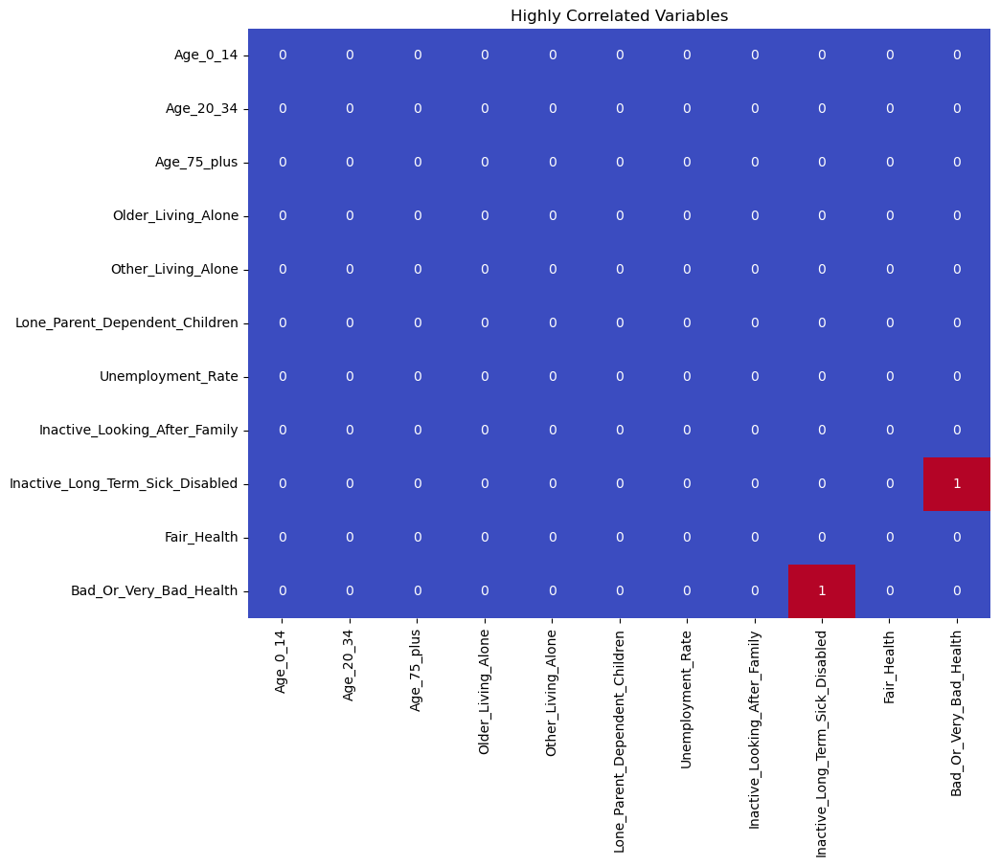

In [19]:
threshold = 0.7

highly_correlated = (corr.abs() > threshold) & (corr.abs() < 1.0)

plt.figure(figsize=(10, 8))
sns.heatmap(highly_correlated, cmap="coolwarm", cbar=False, annot=True)
plt.title("Highly Correlated Variables")
plt.show()

In [20]:
# There is only one pair that has a correlation higher than 0.7 (Bad_Or_Very_Bad_Health & Inactive_Long_Term_Sick_Disabled), we 
# will only keep the first one
drop_cols = ["Inactive_Long_Term_Sick_Disabled"] 

z_score_df = z_score_df.drop(drop_cols, axis=1)

z_score_df.fillna(z_score_df.mean(), inplace=True)

z_score_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3325 entries, 0 to 3324
Data columns (total 10 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   Age_0_14                        3325 non-null   float64
 1   Age_20_34                       3325 non-null   float64
 2   Age_75_plus                     3325 non-null   float64
 3   Older_Living_Alone              3325 non-null   float64
 4   Other_Living_Alone              3325 non-null   float64
 5   Lone_Parent_Dependent_Children  3325 non-null   float64
 6   Unemployment_Rate               3325 non-null   float64
 7   Inactive_Looking_After_Family   3325 non-null   float64
 8   Fair_Health                     3325 non-null   float64
 9   Bad_Or_Very_Bad_Health          3325 non-null   float64
dtypes: float64(10)
memory usage: 259.9 KB


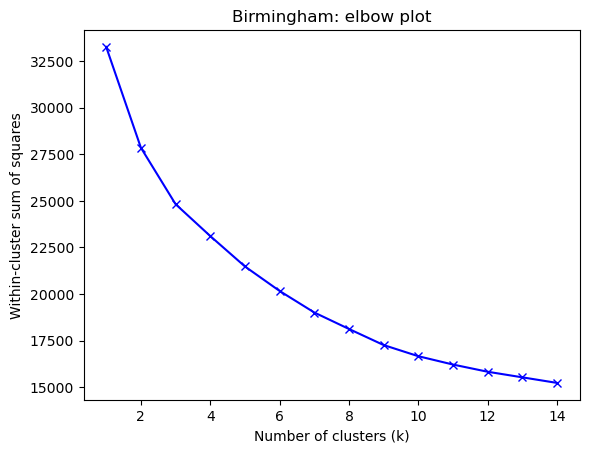

In [21]:
# Testing the optimum amount of clustering using the elbow method
Sum_of_squared_distances = []
K_range = range(1, 15)

for k in K_range:
    km = KMeans(n_clusters=k, n_init=25, random_state=RANDOM_SEED)
    km.fit(z_score_df)
    Sum_of_squared_distances.append(km.inertia_)

plt.plot(K_range, Sum_of_squared_distances, "bx-")
plt.xlabel("Number of clusters (k)")
plt.ylabel("Within-cluster sum of squares")
plt.title("Birmingham: elbow plot")
plt.show()

In [22]:
# It's actually difficult to find a well-represented "elbow," but I will try using K=5
K = 5 

kmeans = KMeans(n_clusters=K, n_init=25, random_state=RANDOM_SEED)
kmeans.fit(z_score_df)

labels = kmeans.predict(z_score_df)

cluster_labels = pd.Series(
    labels,
    index=z_score_df.index,
    name="Cluster"
)

cluster_labels.value_counts().sort_index()

Cluster
0     297
1     395
2     854
3    1397
4     382
Name: count, dtype: int64

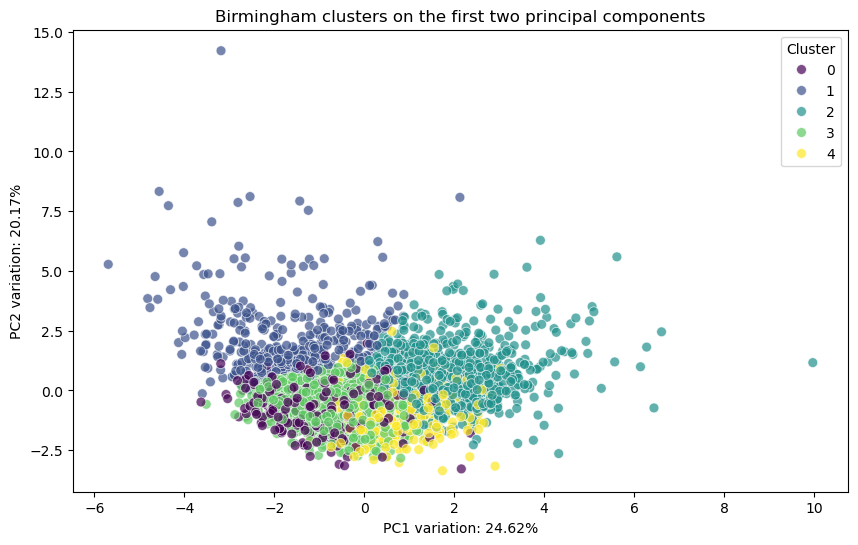

In [23]:
# PCA
pca = PCA(n_components=2).fit(z_score_df)
pca_result = pca.transform(z_score_df)
variance_ratio = pca.explained_variance_ratio_

plt.figure(figsize=(10, 6))

sns.scatterplot(
    x=pca_result[:, 0],
    y=pca_result[:, 1],
    hue=labels,
    palette="viridis",
    s=50,
    alpha=0.7
)

plt.title("Birmingham clusters on the first two principal components")
plt.xlabel(f"PC1 variation: {variance_ratio[0] * 100:.2f}%")
plt.ylabel(f"PC2 variation: {variance_ratio[1] * 100:.2f}%")
plt.legend(title="Cluster")
plt.show()

In [24]:
# Creating a cluster centers table
cluster_centers = pd.DataFrame(
    kmeans.cluster_centers_,
    columns=z_score_df.columns
)

cluster_centers.round(2).style.background_gradient(
    cmap="coolwarm",
    axis=None
)

,Age_0_14,Age_20_34,Age_75_plus,Older_Living_Alone,Other_Living_Alone,Lone_Parent_Dependent_Children,Unemployment_Rate,Inactive_Looking_After_Family,Fair_Health,Bad_Or_Very_Bad_Health
0,-0.050000,-0.410000,0.130000,-0.600000,2.220000,-0.630000,-0.400000,-0.330000,-0.360000,-0.330000
1,-1.010000,-0.590000,1.720000,0.030000,-0.060000,0.030000,-0.120000,-0.500000,1.340000,1.150000
2,0.970000,0.330000,-0.640000,0.260000,-0.200000,-0.030000,0.900000,1.140000,0.370000,0.530000
3,-0.160000,-0.450000,0.090000,-0.010000,-0.270000,0.160000,-0.460000,-0.410000,-0.430000,-0.470000
4,-0.490000,1.830000,-0.790000,-0.130000,-0.250000,-0.080000,0.110000,-0.290000,-0.370000,-0.380000


The PCA plot shows partial separation among the five K-means clusters. PC1 explains 24.62% of the variation in the standardised census variables and PC2 explains 20.17%, giving a combined total of 44.79%. Cluster 1 lies mainly towards the upper left, while Cluster 2 is concentrated further to the right. Clusters 0, 3 and 4 overlap more in the lower central part of the plot. Because K-means used all ten variables, this overlap shows that these groups have similar scores on the two components displayed. 

The cluster centres table shows that Cluster 0 stands out for its high share of other one-person households (+2.22), alongside a below-average share of older one-person households (−0.60). Cluster 1 has a higher share of residents aged 75 or over (+1.72) and higher shares reporting fair health (+1.34) or bad or very bad health (+1.15). Cluster 2 has a higher share of children aged 0–14 (+0.97), higher unemployment (+0.90) and a higher share of residents who are economically inactive because they look after their home or family (+1.14). Cluster 3 has a less pronounced profile, with below-average unemployment (−0.46) and a below-average share reporting bad or very bad health (−0.47). Cluster 4 stands out for its high share of adults aged 20–34 (+1.83) and its lower share of residents aged 75 or over (−0.79).

Cluster 3 had a less pronounced profile, with most of its centre values relatively close to the Birmingham Output Area average. I therefore tested \(k=4\) to see whether a simpler solution would preserve the main neighbourhood profiles.

In [25]:
# Testing 4 clusters
kmeans_4 = KMeans(n_clusters=4, n_init=25, random_state=RANDOM_SEED)
kmeans_4.fit(z_score_df)

labels_4 = kmeans_4.predict(z_score_df)

cluster_labels_4 = pd.Series(
    labels_4,
    index=z_score_df.index,
    name="Cluster"
)

cluster_labels_4.value_counts().sort_index()

Cluster
0     341
1     534
2     938
3    1512
Name: count, dtype: int64

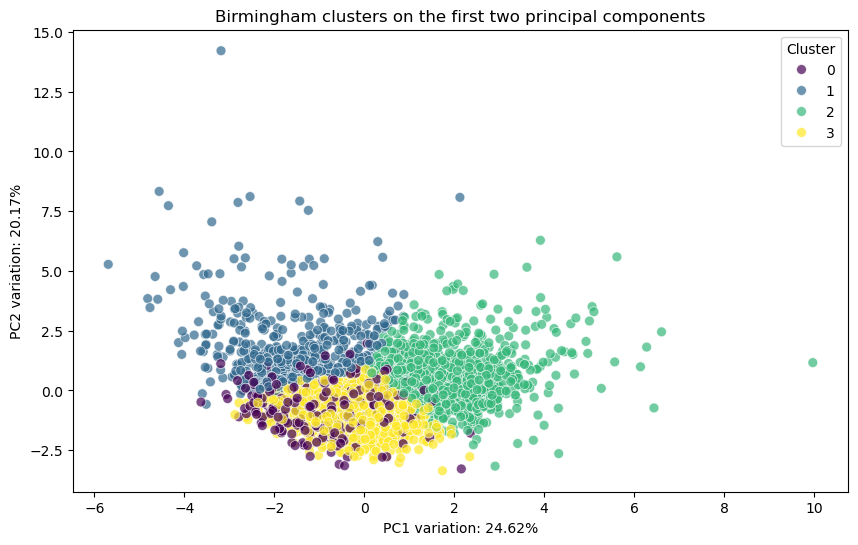

In [26]:
pca = PCA(n_components=2).fit(z_score_df)
pca_result = pca.transform(z_score_df)
variance_ratio = pca.explained_variance_ratio_

plt.figure(figsize=(10, 6))

sns.scatterplot(
    x=pca_result[:, 0],
    y=pca_result[:, 1],
    hue=labels_4,
    palette="viridis",
    s=50,
    alpha=0.7
)

plt.title("Birmingham clusters on the first two principal components")
plt.xlabel(f"PC1 variation: {variance_ratio[0] * 100:.2f}%")
plt.ylabel(f"PC2 variation: {variance_ratio[1] * 100:.2f}%")
plt.legend(title="Cluster")
plt.show()

In [27]:
# Creating a cluster centers table
cluster_centers_4 = pd.DataFrame(
    kmeans_4.cluster_centers_,
    columns=z_score_df.columns
)

cluster_centers_4.round(2).style.background_gradient(
    cmap="coolwarm",
    axis=None
)

,Age_0_14,Age_20_34,Age_75_plus,Older_Living_Alone,Other_Living_Alone,Lone_Parent_Dependent_Children,Unemployment_Rate,Inactive_Looking_After_Family,Fair_Health,Bad_Or_Very_Bad_Health
0,-0.080000,-0.390000,0.120000,-0.500000,2.080000,-0.580000,-0.410000,-0.360000,-0.390000,-0.360000
1,-0.920000,-0.590000,1.520000,0.090000,-0.120000,-0.010000,-0.180000,-0.510000,1.080000,0.860000
2,0.840000,0.510000,-0.670000,0.250000,-0.190000,-0.040000,0.920000,1.070000,0.330000,0.470000
3,-0.180000,-0.020000,-0.140000,-0.080000,-0.310000,0.160000,-0.410000,-0.410000,-0.500000,-0.510000


With five clusters, Cluster 4 had a distinctly high share of adults aged 20–34, with a centre of +1.83 standard deviations above the Birmingham Output Area average. In the four-cluster solution, the highest centre for this variable was +0.51, which means a distinctive demographic group is missing. Therefore, I retained K=5 for the analysis. 

In [ ]:
# Mapping the final cluster groups
final_df = pd.concat(
    [birmingham_results, cluster_labels],
    axis=1
)

final_df.explore(
    column="Cluster",
    categorical=True,
    cmap="Set2",
    tiles="OpenStreetMap",
    style_kwds={
        "weight": 0.4,
        "color": "#666666",
        "fillOpacity": 0.8
    },
    tooltip=["GeographyC", "Cluster"]
)

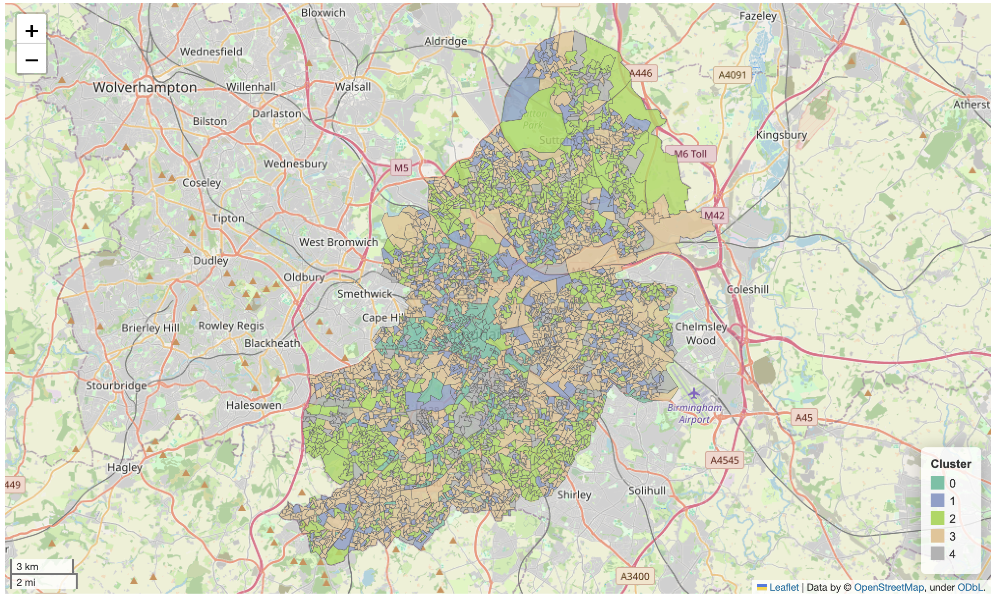

In [ ]:
# Rename the clusters and plot again
def rename_column(x):
    x = str(x)
    x = x.replace("0", "High share of other one-person households")
    x = x.replace("1", "Older residents and poorer reported health")
    x = x.replace("2", "More children and higher unemployment")
    x = x.replace("3", "Lower unemployment and better reported health")
    x = x.replace("4", "High share of young adults")
    return x

final_df["Cluster_name"] = final_df["Cluster"].apply(rename_column)

final_df.explore(
    column="Cluster_name",
    categorical=True,
    cmap="Set2",
    tiles="OpenStreetMap",
    style_kwds={
        "weight": 0.4,
        "color": "#666666",
        "fillOpacity": 0.8
    },
    tooltip=["GeographyC", "Cluster_name"] + z_score_df.columns.tolist()
)

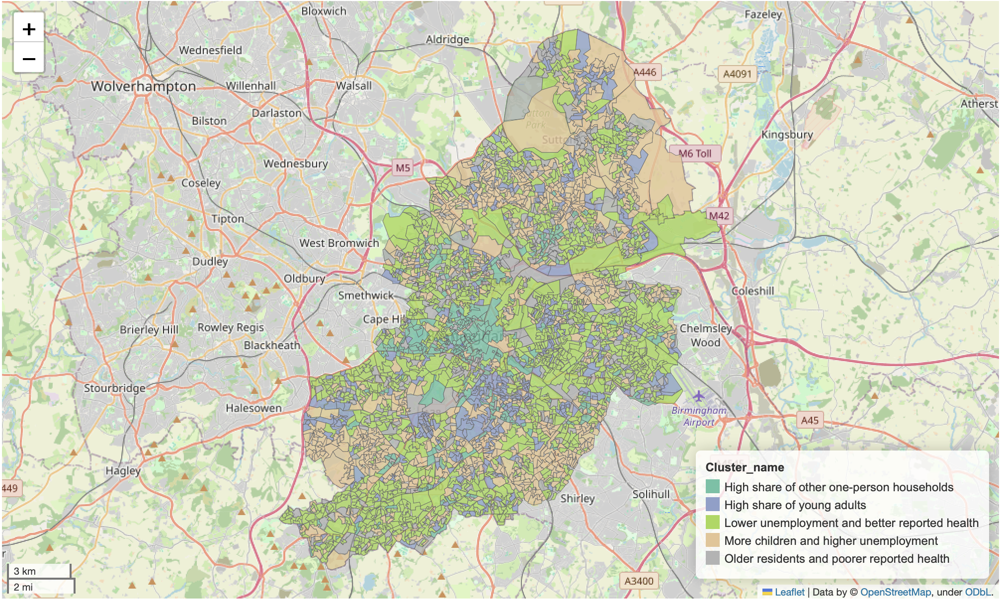

**Challenges in determining the number of clusters**: It was difficult to identify and quantify a sharp decline in the gradient from the smooth elbow plot. Trying 5 clusters was really an estimate. The PCA graphs show significant overlap between three of the groups; however, the cluster centres showed distinct census profiles across the full set of variables, which means it is still useful to keep 5 clusters instead of 4. 

**Application of this geodemographics classification**: Areas with more residents aged 75 or over and poorer reported health could be assessed for access to primary care, community health services and accessible transport. Areas with more children and higher unemployment could be assessed for childcare provision and employment support. The clusters describe area averages, so service decisions would also need evidence on existing provision, travel times and residents’ own experiences.